# iLEEN → JAX-FEM: Plattenstatik, lastfallweise gerechnet und bemessen

Dieses Notebook rechnet eine Decke, die im Zeichenmodus von **iLEEN**
(iLEEN, Reiter *Plan*) vorbereitet wurde — von der Exportdatei bis zur
gestaffelten Bewehrung.

**Der Weg dorthin, im Viewer:**

| Schritt | Werkzeug | Was entsteht |
|---|---|---|
| 1 | *Plan → Grundriss* | Schnittfiguren des Geschosses |
| 2 | ⬠ Systemfläche | Umriss der zu rechnenden Platte, Dicke, Material |
| 3 | △ Auflager | Linienlager auf den Wandachsen, Punktlager auf Stützen |
| 4 | ▦ ⇉ ↓ Lasten | Flächen-, Linien- und Einzellasten je Lastfall |
| 5 | ⬭ ⚯ Positionen | Positionsnummern, mit Bauteilen verknüpft |
| 6 | **FEM** | `…_FEM.json` — die Datei, die hier eingelesen wird |

**Was gerechnet wird:**

| Teil | Inhalt | Abschnitt |
|---|---|---|
| Platte | Biegung senkrecht zur Ebene, je Lastfall getrennt | 4 – 9 |
| Laststellung | ungünstige Stellung über Einflussflächen | 10 |
| Querkraft | Feld, Auflagerbilanz, v_Rd,c ohne Bewehrung | 11 – 12 |
| Scheibe | Wind und Schiefstellung in der Deckenebene, Schub und Zug | 13 – 16 |
| Bemessung | Biegung mit Normalkraft, Mindestbewehrung, Staffelung | 17 – 18 |
| Unterzüge | Plattenbalken: M und V über den Querschnitt, Bügel, Staffelung | 19 |
| Nachweise | Durchstanzen, Rissbreite, Verformung im Zustand II | 8, 20 |

Der Rückweg läuft über die IFC-GlobalId: jede Position führt die GlobalIds
ihrer Bauteile mit, Ergebnisse lassen sich damit wieder am Modell zeigen.

---

## Drei Dinge vorweg, die das Ergebnis bestimmen

**1. Gerechnet wird ein 3D-Körper aus HEX8, keine Plattenelemente.** JAX-FEM
bringt keine mit. Daraus folgt die Netzregel: die Elementgröße darf höchstens
die halbe Plattendicke betragen, besser ein Viertel — sonst versteifen die
Elemente unter Biegung (Schublocking), und Momente *wie* Durchbiegung fallen
zu klein aus, also auf der unsicheren Seite.

| Elementgröße | erreichtes Feldmoment |
|---|---|
| Δ = h | 66 % |
| Δ = h/2 | 89 % |
| Δ = h/4 | 97 % |

Mehr Lagen über die Dicke helfen dagegen nicht — zwei und vier liefern
dasselbe. In der Ebene verfeinern, nicht in der Höhe.

**2. Lastfallweise, nicht kombiniert.** Die Steifigkeitsmatrix wird *einmal*
aufgestellt und zerlegt; jeder Lastfall ist danach ein Rückwärtseinsetzen von
Millisekunden. Die Kombinationen entstehen durch Überlagerung der Lösungen —
dasselbe Ergebnis wie eine Neurechnung, aber jeder Anteil bleibt bis zur
Bemessung einzeln sichtbar. Das ist die Voraussetzung für Einhüllende und für
die ungünstige Laststellung.

**3. Ein Unterzug ist kein Sonderfall der Platte.** Er steht im selben Netz —
seine Rasterspalten bekommen zusätzliche Elementlagen — und versteift die Decke
dadurch richtig. Ausgewertet werden muss er aber anders: „Moment je Meter
Breite" ist im Steg keine Größe. Abschnitt 19 integriert stattdessen über den
ganzen Querschnitt und bemisst ihn als Plattenbalken. In den Karten der
Abschnitte 9 bis 18 bleibt der Balkenstreifen deshalb **leer** — das ist keine
Lücke, sondern die Zuständigkeitsgrenze.

**4. Platte und Scheibe sind zwei Systeme.** Sie haben verschiedene Lager:
die Platte wird nur in der Senkung gehalten (sonst entstünde eine
Gewölbewirkung, die es im gerissenen Stahlbeton nicht gibt), die Scheibe
zusätzlich in Wandrichtung an den aussteifenden Wänden. Zusammengeführt wird
erst bei der Bemessung — Moment und Normalkraft am selben Querschnitt.

In [1]:
import sys, json, time, logging
from pathlib import Path

# Die Wurzel ist das Verzeichnis, in dem `ileen` liegt — gesucht wird von hier
# aufwärts. Das Notebook steht an zwei Orten: im iLEEN-Backend unter
# `notebooks/` und in JaxFEM unter `Notebooks/`. Ein Vergleich des
# Verzeichnisnamens hätte an einem der beiden Orte an der Groß- und
# Kleinschreibung gelegen.
WURZEL = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'ileen').is_dir()),
              Path.cwd())
sys.path.insert(0, str(WURZEL))

import numpy as np
import matplotlib.pyplot as plt

from ileen import plate, scheibe, unterzug, zeichnen
from ileen import beton as bt
from ileen.loeser import Loeser, kombiniere

# JAX-FEM protokolliert je Assemblierung mehrere Zeilen; interessant ist davon
# nur, was schiefgeht.
logging.getLogger('jax_fem').setLevel(logging.WARNING)
zeichnen.stil()
print('ileen bereit —', WURZEL)

       __       ___      ___   ___                _______  _______ .___  ___. 
      |  |     /   \     \  \ /  /               |   ____||   ____||   \/   | 
      |  |    /  ^  \     \  V  /      ______    |  |__   |  |__   |  \  /  | 
.--.  |  |   /  /_\  \     >   <      |______|   |   __|  |   __|  |  |\/|  | 
|  `--'  |  /  _____  \   /  .  \                |  |     |  |____ |  |  |  | 
 \______/  /__/     \__\ /__/ \__\               |__|     |_______||__|  |__| 
                                                                              

ileen bereit — /Users/philippschafer/Projekte/iLEEN/backend


## 1. Modell und Stellschrauben

`QUELLE` bestimmt, was gerechnet wird:

* `'beispiel'` — die mitgelieferte L-förmige Geschossdecke (88 m², zwei Felder,
  Innenwand, Stütze, vier Lastfälle). Sie zeigt alle Abschnitte dieses
  Notebooks und läuft in etwa einer Minute.
* `'unterzug'` — eine Hallendecke 12 × 8 m mit einem zweifeldrigen Unterzug
  30/60 über einer Mittelstütze. Sie ist die Vorlage für Abschnitt 19; die
  Geschossdecke oben hat keinen Unterzug, dieser Abschnitt bliebe dort leer.
* `'downloads'` — die neueste `…_FEM.json` aus `~/Downloads`, also der eigene
  Export aus dem Viewer.
* ein Pfad — jede andere Datei.

Alles Weitere sind die Annahmen, die der Plan nicht enthält: Windzone,
Geschosshöhe, Expositionsklasse, Bewehrungsdurchmesser. Sie stehen hier
zusammen, damit man sie an einer Stelle ändert und nicht im Text sucht.

In [2]:
QUELLE = 'downloads'         # 'downloads' | 'beispiel' | 'unterzug' | '/pfad/zur/datei_FEM.json'

# --- Netz
ELEMENTGROESSE = None        # None = Plattendicke / 2 (die Regel aus der Vorbemerkung)
LAGEN = 2

# --- Annahmen, die im Plan nicht stehen
WINDZONE        = 2          # 1…4, Binnenland
GEBAEUDEHOEHE   = 12.0       # m, für den Staudruck
GESCHOSSHOEHE   = 3.2        # m, Einzugshöhe der Fassade an dieser Decke
GESCHOSSE_UEBER = 3          # Geschosse über dieser Decke (Schiefstellung)
EXPOSITION      = 'XC1'      # Innenbauteil
DURCHMESSER_MM  = 10         # Bewehrungsdurchmesser der Grundlage
KRIECHZAHL      = 2.0        # φ für den Verformungsnachweis

# --- Unterzüge (Abschnitt 19). Die Deckung ist dort größer als in der Platte:
# ein Balken hat Bügel, und die Längsbewehrung liegt hinter ihnen.
EXPOSITION_BALKEN = 'XC1'
BUEGEL_MM         = 8        # Bügeldurchmesser, geht in die Nutzhöhe ein
LAENGS_MM         = 16       # Annahme für die Nutzhöhe, vor der Stabwahl

BEISPIEL = WURZEL / 'ileen' / 'beispiel_geschoss_fem.json'
BEISPIEL_UZ = WURZEL / 'ileen' / 'beispiel_unterzug_fem.json'

if QUELLE == 'downloads':
    gefunden = sorted(Path.home().glob('Downloads/*_FEM.json'),
                      key=lambda f: f.stat().st_mtime, reverse=True)
    if gefunden:
        DATEI = gefunden[0]
    else:
        print('keine …_FEM.json in ~/Downloads — gerechnet wird das Beispiel\n')
        DATEI = BEISPIEL
elif QUELLE == 'beispiel':
    DATEI = BEISPIEL
elif QUELLE == 'unterzug':
    DATEI = BEISPIEL_UZ
else:
    DATEI = Path(QUELLE)

modell = plate.lade(DATEI)
print('gelesen:', DATEI.name, '\n')
print(modell.bericht())

platte = modell.platte()
E  = platte['material']['E_kNm2']
nu = platte['material']['nu']
h  = platte['dicke_m']
ELEMENTGROESSE = ELEMENTGROESSE or h / 2

gelesen: Grundriss_OG2_OPL_ArchiCAD_ifc2x3.ifc_Untersicht_1zu100_FEM.json 

Grundriss OG2 — OPL_ArchiCAD_ifc2x3.ifc
  Systemflächen : 4  (gerechnet: P1, 594.5 m², d = 20 cm, C25/30)
  Lastfälle     : q1 (Q)
  Lasten        : 5
  Auflager      : 24
  Positionen    : 4


## 2. Was im Plan steht

Vor dem Rechnen ein Blick auf die Eingabe. Was hier falsch aussieht, ist im
Ergebnis nicht mehr zu erkennen — eine vergessene Auflagerlinie erzeugt keine
Fehlermeldung, sondern ein plausibel aussehendes, falsches Moment.

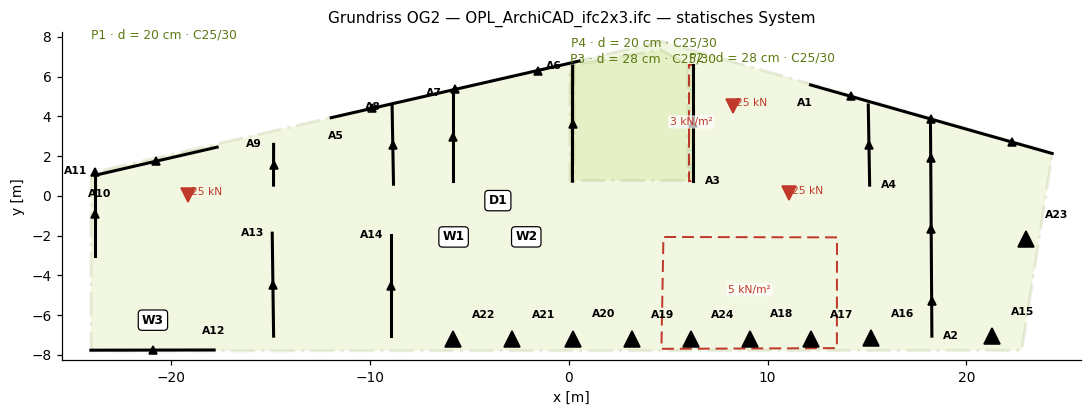

In [3]:
fig, ax = plt.subplots(figsize=(10, 6.5))
zeichnen.plan(ax, modell)
ax.set_title(f'{modell.titel} — statisches System')
plt.tight_layout(); plt.show()

### Dieselbe Zeichnung, nach Lastfällen getrennt

Ein Bild je Lastfall — das ist die erste Stelle, an der die lastfallweise
Rechnung sichtbar wird, und die zuverlässigste Kontrolle der Eingabe: hier
fällt auf, wenn eine Nutzlast im falschen Lastfall liegt oder ein Raum
unbelastet blieb.

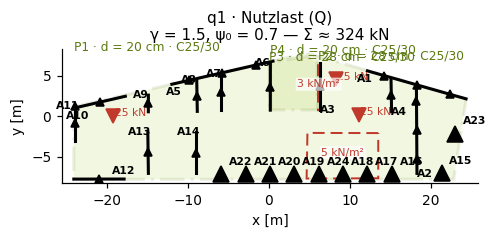

In [4]:
mit_lasten = [f for f in modell.lastfaelle
              if any(l['lastfall'] == f['id'] for l in modell.lasten)]

spalten = min(3, max(1, len(mit_lasten)))
zeilen = int(np.ceil(len(mit_lasten) / spalten))
fig, achsen = plt.subplots(zeilen, spalten, figsize=(4.6 * spalten, 3.6 * zeilen),
                           squeeze=False)

for ax, fall in zip(achsen.ravel(), mit_lasten):
    nur = {**modell.daten, 'lasten': [l for l in modell.lasten if l['lastfall'] == fall['id']]}
    teil = plate.Modell(daten=nur, quelle=modell.quelle)
    zeichnen.plan(ax, teil, positionen=False, beschriften=True)
    summe = sum(l['wert'] * (plate.flaeche(np.asarray(l['polygon'])) if l['typ'] == 'flaeche'
                else (np.linalg.norm(np.diff(np.asarray(l['polylinie']), axis=0), axis=1).sum()
                      if l['typ'] == 'linie' else 1.0))
                for l in nur['lasten'])
    ax.set_title(f"{fall['id']} · {fall['name']} ({fall['art']})\n"
                 f"γ = {fall.get('gamma', 1.5)}, ψ₀ = {fall.get('psi0', 0.7)} — Σ ≈ {summe:.0f} kN")

for ax in achsen.ravel()[len(mit_lasten):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Netz

Das Raster folgt der Systemfläche; Zellen, deren Mittelpunkt außerhalb liegt,
fallen weg. Für rechteckige und L-förmige Deckenfelder ist das exakt — nur
schräge Ränder bekommen eine Treppe. Wer sie braucht, nimmt
`plate.vernetze_gmsh(modell)`: dieselbe Rückgabe, randtreu vernetzt.

<Netz raster: 181011 Knoten, 119392 HEX8, Δ ≈ 0.100 m, d = 0.200 m> → 543033 Freiheitsgrade
! 543k Freiheitsgrade: die Zerlegung dauert einige Minuten und braucht mehrere GB. Für einen ersten Durchgang ELEMENTGROESSE = 0.20 setzen (dann sind die Momente allerdings zu klein).


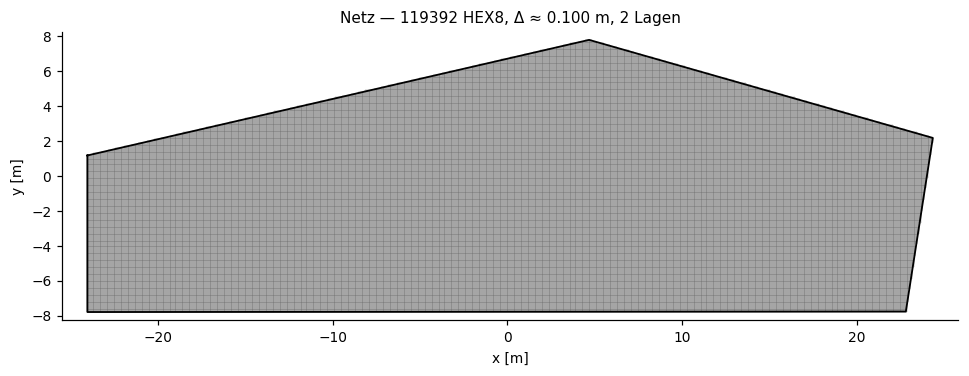

In [5]:
netz = plate.vernetze(modell, groesse=ELEMENTGROESSE, lagen=LAGEN)
freiheitsgrade = netz.n_knoten * 3
print(netz, f'→ {freiheitsgrade} Freiheitsgrade')

# Die Zerlegung wächst überproportional mit den Freiheitsgraden — an Zeit und
# vor allem an Speicher. Wer eine große Decke fein vernetzt, sollte den ersten
# Durchgang gröber rechnen und erst danach verfeinern.
if freiheitsgrade > 150_000:
    print(f'! {freiheitsgrade/1000:.0f}k Freiheitsgrade: die Zerlegung dauert einige Minuten '
          f'und braucht mehrere GB. Für einen ersten Durchgang ELEMENTGROESSE = '
          f'{max(ELEMENTGROESSE * 2, h):.2f} setzen (dann sind die Momente allerdings zu klein).')

# Unterzüge stecken als zusätzliche Elementlagen im Netz — hier steht, wie viele
# Spalten davon betroffen sind. Sind es null, obwohl der Plan Unterzüge zeigt,
# ist ihre Höhe nicht größer als die Plattendicke (siehe Warnung darunter).
balken = unterzug.finde(modell, netz)
if modell.balken:
    anteil = 100 * float(np.mean(netz.balken_spalten)) if netz.balken_spalten is not None else 0.0
    print(f'{len(modell.balken)} Unterzug/Überzug im Plan, {len(balken)} rechenbar, '
          f'{anteil:.1f} % der Elemente im Balkenstreifen')
    for b in balken:
        print('   ', b)

fig, ax = plt.subplots(figsize=(9, 5.5))
zeichnen.netzbild(ax, netz)
plt.tight_layout(); plt.show()

for hinweis in modell.warnungen:
    print('!', hinweis)

## 4. Jeder Lastfall für sich

Die Einwirkungen werden als **Volumenkraft** angesetzt, nicht als
Oberflächenlast: so hängt die Steifigkeitsmatrix nicht an der Last, und eine
Zerlegung reicht für alle Lastfälle. Eine Flächenlast q kommt als q/t in die
oberste Elementlage der Höhe t; das Eigengewicht ist ohnehin eine
Volumenkraft und wird über die volle Dicke mit der Wichte angesetzt.

Das Eigengewicht bekommt dabei den eigenen Schlüssel `EG` — im Plan ist es
nicht gezeichnet, in der Kombination muss es aber einzeln gewichtet werden.

In [6]:
felder = plate.einzelfelder(modell, netz)
# `plate.zellvolumen()` statt `groesse² · dz`: dx und dy des Rasters sind nur
# zufällig gleich (die Bounding Box wird in ganze Zellen geteilt), und ein
# halbes Prozent Unterschied in der Zellfläche wäre hier ein halbes Prozent
# Last, das keine Probe findet.
zelle = plate.zellvolumen(netz)

print(f"{'Lastfall':10s} {'Art':4s} {'Σ F_z [kN]':>12s}   Beschreibung")
print('-' * 62)
summen = {}
for kennung, feld in felder.items():
    summen[kennung] = float((feld[:, 2] * zelle).sum())
    fall = modell.lastfall(kennung) if kennung != 'EG' else {'art': 'G', 'name': 'Eigengewicht Platte'}
    print(f"{kennung:10s} {fall.get('art', '?'):4s} {summen[kennung]:12.1f}   {fall.get('name', '')}")
print('-' * 62)
print(f"{'Summe':10s} {'':4s} {sum(summen.values()):12.1f}   charakteristisch, ohne γ")

Lastfall   Art    Σ F_z [kN]   Beschreibung
--------------------------------------------------------------
EG         G         -2976.1   Eigengewicht Platte
q1         Q          -324.3   Nutzlast
--------------------------------------------------------------
Summe                -3300.3   charakteristisch, ohne γ


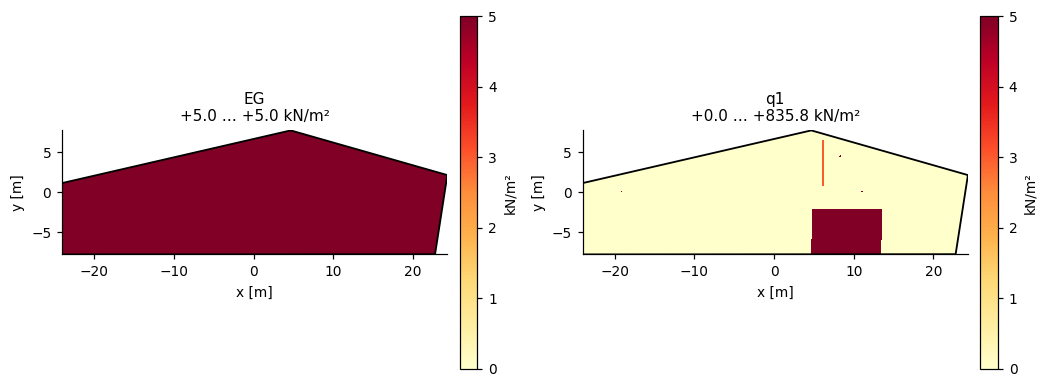

In [7]:
# Die Lastfelder als Karten — je Lastfall die Flächenlast, die im Modell ankommt
mitten = netz.points[netz.cells].mean(axis=1)
# `plate.oberste_lage_z()` statt des Netzmaximums: bei einem Überzug reicht das
# Netz höher als die Deckenoberfläche, und das Maximum träfe nur den Rippenkopf.
oben = mitten[:, 2] >= plate.oberste_lage_z(netz) - 1e-9
hoehe = plate.lagenhoehe(netz)

spalten = min(3, len(felder))
zeilen = int(np.ceil(len(felder) / spalten))
fig, achsen = plt.subplots(zeilen, spalten, figsize=(4.8 * spalten, 3.6 * zeilen), squeeze=False)

for ax, (kennung, feld) in zip(achsen.ravel(), felder.items()):
    if kennung == 'EG':
        q = -feld[oben, 2] * netz.dicke        # Wichte über die volle Dicke
    else:
        q = -feld[oben, 2] * hoehe
    zeichnen.karte(ax, mitten[oben][:, :2], q, netz, titel=f'{kennung}',
                   einheit='kN/m²', symmetrisch=False, cmap='YlOrRd')

for ax in achsen.ravel()[len(felder):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 5. Ein System, eine Zerlegung

Jetzt die Randbedingungen und der Löser. Der teure Schritt — Matrix aufstellen
und zerlegen — passiert genau einmal; danach kostet jeder Lastfall
Millisekunden.

**Die Probe steht direkt dahinter.** R = K·u − f: an freien Knoten null, an
gehaltenen die Auflagerkraft. Ihre Summe muss die aufgebrachte Last sein. Das
ist die schärfste Prüfung, die eine FE-Rechnung zulässt, und sie kostet eine
Matrixmultiplikation.

In [ ]:
bc_info, lagerung = plate.randbedingungen(modell, netz)
print('Lagerung:', lagerung)

t0 = time.time()
loeser = Loeser(netz, E, nu, bc_info)
print(f'Matrix aufgestellt und zerlegt: {time.time() - t0:.1f} s ({loeser.n_dof} DOF)')

t0 = time.time()
loesungen, vektoren = loeser.loese_alle(felder)
print(f'{len(felder)} Lastfälle gelöst: {time.time() - t0:.2f} s '
      f'({(time.time() - t0) / max(len(felder), 1) * 1000:.0f} ms je Lastfall)')

print(f"\n{'Lastfall':10s} {'Σ Last [kN]':>12s} {'Σ Auflager [kN]':>16s} {'Abweichung':>12s}")
for kennung in felder:
    p = loeser.probe(loesungen[kennung], vektoren[kennung])
    print(f"{kennung:10s} {p['last_kN'][2]:12.2f} {p['auflager_kN'][2]:16.2f} "
          f"{p['abweichung_rel']:12.1e}")

Lagerung: {'eingespannt': 0, 'senkung_gehalten': 1086, 'starrkoerper': 3, 'toleranz': 0.059949421487603294}


## 6. Was jeder Lastfall bewirkt

Dieselbe Platte, vier Einwirkungen, vier Verformungsbilder. Sie sind der
Grund, warum lastfallweise gerechnet wird: die Nutzlast eines Feldes hebt das
Nachbarfeld an — genau die Wirkung, die in Abschnitt 10 zur ungünstigen
Laststellung führt und in einer fertig kombinierten Rechnung unsichtbar bleibt.

In [ ]:
# `plate.unterseiten_knoten()` statt `z == z.min()`: unter einem Unterzug liegt
# die Unterseite lokal tiefer, und ein globales Minimum träfe dann **nur** den
# Balkenfuß — die Durchbiegungskarte bestünde aus einem Strich.
unten = plate.unterseiten_knoten(netz)
xy_knoten = netz.points[unten][:, :2]

spalten = min(3, len(loesungen))
zeilen = int(np.ceil(len(loesungen) / spalten))
fig, achsen = plt.subplots(zeilen, spalten, figsize=(4.8 * spalten, 3.6 * zeilen), squeeze=False)

for ax, (kennung, u) in zip(achsen.ravel(), loesungen.items()):
    w = -np.asarray(u)[unten, 2] * 1000
    zeichnen.karte(ax, xy_knoten, w, netz, titel=f'{kennung} — w',
                   einheit='mm', symmetrisch=True, cmap='RdYlBu')

for ax in achsen.ravel()[len(loesungen):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 7. Kombinationen

`kombinationen()` bildet die Grundkombination nach DIN EN 1990 Gl. 6.10 — je
veränderlichem Lastfall einmal als Leiteinwirkung — sowie die drei
Gebrauchskombinationen. γ und ψ stehen am Lastfall und kommen aus dem Plan;
im Fenster „⚖ Lastfälle" lassen sie sich dort ändern.

Lastfälle, zu denen nichts gezeichnet wurde, fallen heraus: das Frontend legt
fünf Standardlastfälle an, gezeichnet wird meist in zweien, und leere
Kombinationen würden nur die Auswahl der maßgebenden verfälschen.

**Kombiniert werden die Lösungen, nicht die Lasten.** u(GZT) = Σ γ_i·u_i —
dasselbe Ergebnis wie eine Neurechnung, für den Preis einer Addition.

In [ ]:
kombis = plate.kombinationen(modell)
name = plate.massgebend(kombis)

breite = max(len(k) for k in kombis)
print(f"{'Kombination':{breite}s}  Faktoren")
for bezeichnung, faktoren in kombis.items():
    zeile = '  '.join(f'{k}·{v:.2f}' for k, v in faktoren.items() if v)
    marke = '  ← maßgebend (GZT)' if bezeichnung == name else ''
    print(f'{bezeichnung:{breite}s}  {zeile}{marke}')

# Superposition: je Kombination eine Lösung und ihre Schnittgrößen
verschiebungen, lastvektoren, schnitte = {}, {}, {}
for bezeichnung, faktoren in kombis.items():
    verschiebungen[bezeichnung] = kombiniere(loesungen, faktoren)
    lastvektoren[bezeichnung] = kombiniere(vektoren, faktoren)
    schnitte[bezeichnung] = plate.schnittgroessen(verschiebungen[bezeichnung], netz, E, nu)

print(f"\n{'Kombination':{breite}s} {'Σ F [kN]':>10s} {'w_max [mm]':>11s} "
      f"{'m_x [kNm/m]':>22s} {'m_y [kNm/m]':>22s}")
for bezeichnung in kombis:
    s = schnitte[bezeichnung]
    w = -np.asarray(verschiebungen[bezeichnung])[:, 2].min() * 1000
    # `plate.hoechstwert()` statt .min()/.max(): im Streifen eines Unterzugs
    # steht NaN, und eine einzige NaN-Stelle machte die ganze Spalte zu NaN.
    print(f'{bezeichnung:{breite}s} {lastvektoren[bezeichnung].reshape(-1, 3)[:, 2].sum():10.0f} '
          f'{w:11.2f} '
          f'{-plate.hoechstwert(-s["m_x"]):10.1f} …{plate.hoechstwert(s["m_x"]):8.1f} '
          f'{-plate.hoechstwert(-s["m_y"]):10.1f} …{plate.hoechstwert(s["m_y"]):8.1f}')

## 8. Durchbiegung

Der Nachweis gehört zur **quasi-ständigen** Kombination, nicht zur
Bemessungskombination des Grenzzustands der Tragfähigkeit.

Als Stützweite gilt nicht die Abmessung des Umrisses — bei einer Decke mit
Innenwand wäre sie doppelt so groß wie die wirkliche Feldweite. Gemessen wird
stattdessen der größte Abstand eines Punktes zum nächsten Auflager,
verdoppelt: beim Einfeldträger genau die Stützweite, bei zwei Feldern die
Feldweite, bei der Flachdecke die Diagonale zwischen den Stützen.

**Und die gerechnete Durchbiegung ist die des ungerissenen Querschnitts.**
Für Stahlbeton ist sie damit um ein Vielfaches zu klein. `beton.zustand_II()`
rechnet sie nach EC2 7.4.3 hoch: Verteilungsbeiwert ζ zwischen ungerissenem
und gerissenem Zustand, dazu das Kriechen über E_c,eff = E_cm/(1+φ).

w_elastisch =  10.01 mm  bei (10.14 | -2.71) m
Stützweite  =  10.43 m  →  Grenzwert l/250 = 41.7 mm


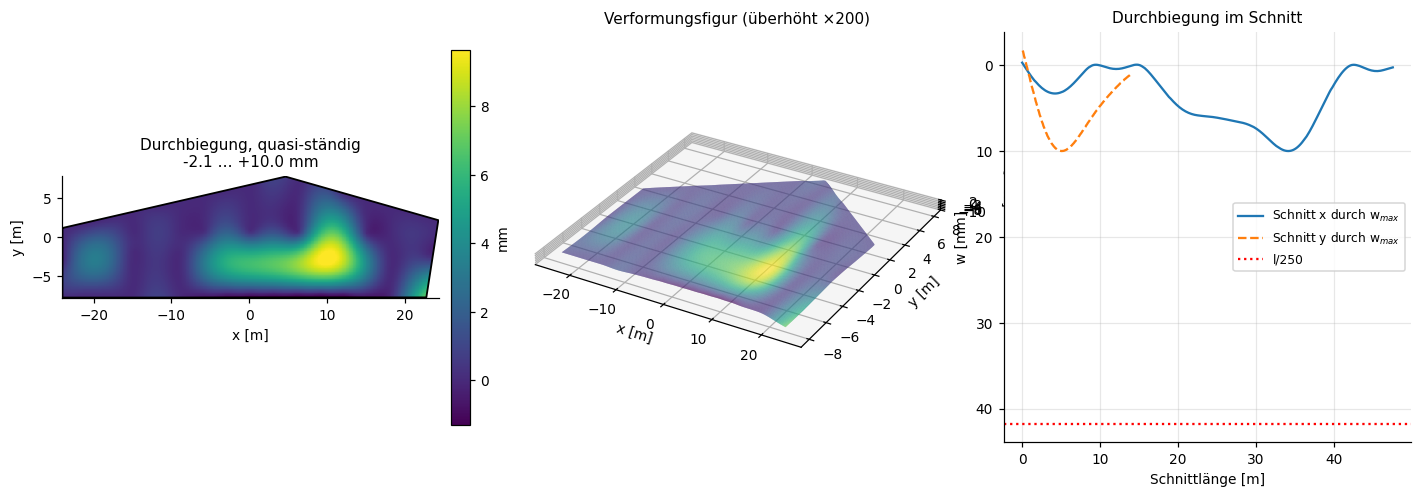

In [ ]:
u_qs = verschiebungen['GZG · quasi-ständig']
ergebnis = plate.durchbiegung(u_qs, netz, modell)

print(f"w_elastisch = {ergebnis['w_max_mm']:6.2f} mm  bei "
      f"({ergebnis['ort'][0]:.2f} | {ergebnis['ort'][1]:.2f}) m")
print(f"Stützweite  = {ergebnis['spannweite_m']:6.2f} m  →  Grenzwert l/250 = "
      f"{ergebnis['grenzwert_mm']:.1f} mm")

fig = plt.figure(figsize=(13, 4.6))
ax1 = fig.add_subplot(1, 3, 1)
zeichnen.karte(ax1, xy_knoten, -np.asarray(u_qs)[unten, 2] * 1000, netz,
               titel='Durchbiegung, quasi-ständig', einheit='mm',
               symmetrisch=False, cmap='viridis')

ax2 = fig.add_subplot(1, 3, 2, projection='3d')
zeichnen.verformungsflaeche(ax2, netz, u_qs, ueberhoehung=200)

ax3 = fig.add_subplot(1, 3, 3)
p = np.asarray(ergebnis['ort'][:2])
for achse, (a, b), stil_ in ((0, ((netz.polygon[:, 0].min(), p[1]), (netz.polygon[:, 0].max(), p[1])), '-'),
                             (1, ((p[0], netz.polygon[:, 1].min()), (p[0], netz.polygon[:, 1].max())), '--')):
    s, w = plate.entlang(xy_knoten, -np.asarray(u_qs)[unten, 2] * 1000, a, b,
                          n=250, netz=netz)
    ax3.plot(s, w, stil_, label=f"Schnitt {'x' if achse == 0 else 'y'} durch w$_{{max}}$")
ax3.axhline(ergebnis['grenzwert_mm'], color='r', ls=':', label='l/250')
ax3.invert_yaxis(); ax3.legend(fontsize=8); ax3.grid(alpha=0.3)
ax3.set_xlabel('Schnittlänge [m]'); ax3.set_ylabel('w [mm]')
ax3.set_title('Durchbiegung im Schnitt')
plt.tight_layout(); plt.show()

## 9. Momente

`schnittgroessen()` liefert m_x, m_y und m_xy in kNm je Meter. Positive Werte
bedeuten Zug an der Unterseite (Feldbewehrung), negative Zug oben
(Stützbewehrung).

Ermittelt werden sie nicht aus der Spannung an einer einzelnen Faser, sondern
durch Anpassung des geradlinigen Spannungsverlaufs über die Dicke mit
anschließender exakter Integration. An einer einachsig gespannten
Kontrollplatte trifft das Verfahren q·l²/8 auf 3 % genau, sobald die
Elementgröße bei einem Viertel der Plattendicke liegt.

**m_xy ist keine Nebengröße.** In den Ecken einer zweiachsig gespannten Platte
sind m_x und m_y klein und m_xy groß — eine Bemessung allein nach m_x und m_y
ließe die Ecke unbewehrt. Abschnitt 17 legt das Drillmoment nach Wood und
Armer auf die beiden Bewehrungsrichtungen um.

**Die Spitzenwerte an Wandenden und einspringenden Ecken sind
Singularitäten.** Dort ist das Moment im mathematischen Modell unendlich; jede
Netzverfeinerung liefert einen größeren Wert, ohne dass die Platte in
Wirklichkeit stärker beansprucht wäre. Bemessen wird deshalb nicht auf den
Größtwert eines einzelnen Elements, sondern auf den über die Auflagerbreite
ausgerundeten Verlauf — EC2 5.3.2.2 lässt bei monolithischem Anschluss den
Wert am Auflagerrand zu. Die Karten kappen die Farbskala am Perzentil und
nennen den wahren Größtwert im Titel; die Bemessungstabelle in Abschnitt 17
weist beide Zahlen aus.

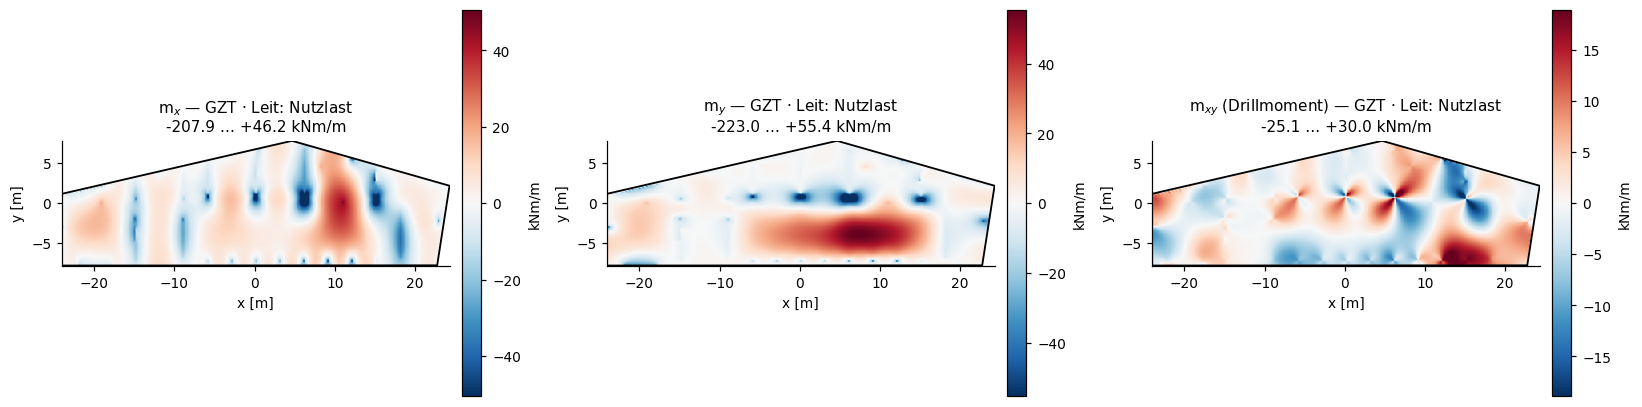

Rot = Zug unten (Feldbewehrung), Blau = Zug oben (Stützbewehrung)


In [ ]:
s = schnitte[name]
xy = s['xy']

fig, achsen = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, schluessel, titel in ((achsen[0], 'm_x', 'm$_x$'), (achsen[1], 'm_y', 'm$_y$'),
                              (achsen[2], 'm_xy', 'm$_{xy}$ (Drillmoment)')):
    zeichnen.karte(ax, xy, s[schluessel], netz,
                   titel=f'{titel} — {name}', einheit='kNm/m')
plt.tight_layout(); plt.show()
print('Rot = Zug unten (Feldbewehrung), Blau = Zug oben (Stützbewehrung)')

### Hauptmomente und Trajektorien

Der Mohrsche Kreis der Platte: m₁ und m₂ sind die Momente in den Richtungen,
in denen kein Drillmoment auftritt. Die Striche folgen den Bahnen, auf denen
die Platte ihre Last zu den Auflagern bringt — parallele Striche heißen
einachsige Tragwirkung, gedrehte zweiachsige.

Legte man die Bewehrung entlang dieser Bahnen, käme man mit dem wenigsten
Stahl aus. Man tut es nicht, weil orthogonale Netze billiger zu verlegen sind
als gekrümmte Scharen — aber das Bild sagt, wie die Platte trägt.

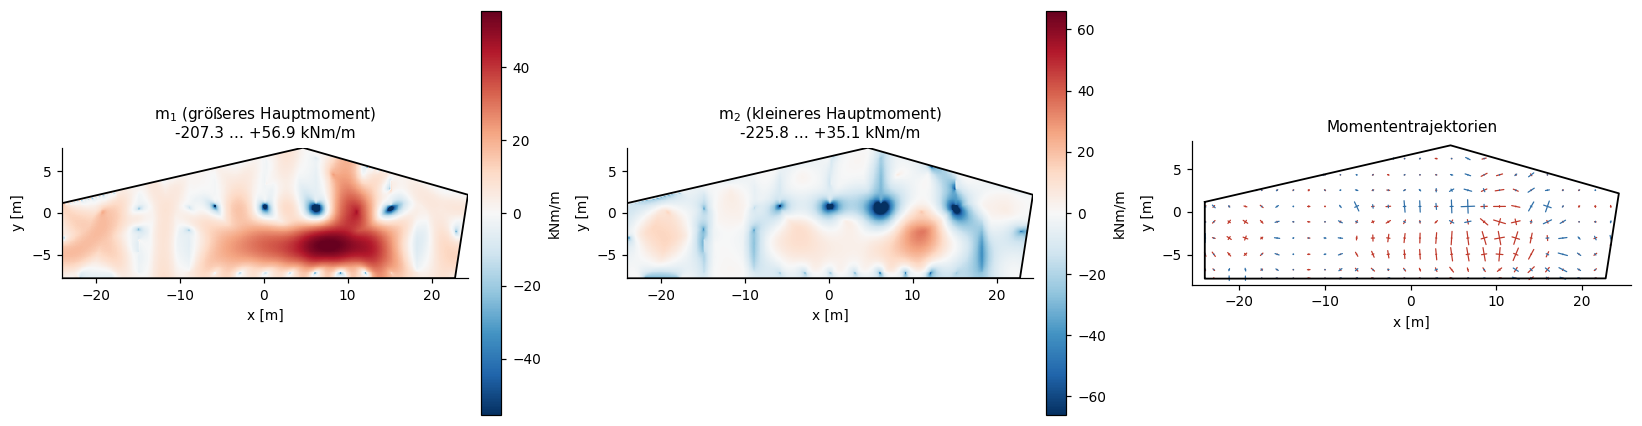

In [ ]:
haupt = plate.hauptmomente(s['m_x'], s['m_y'], s['m_xy'])

fig, achsen = plt.subplots(1, 3, figsize=(15, 4.3))
zeichnen.karte(achsen[0], xy, haupt['m_1'], netz, titel='m$_1$ (größeres Hauptmoment)',
               einheit='kNm/m')
zeichnen.karte(achsen[1], xy, haupt['m_2'], netz, titel='m$_2$ (kleineres Hauptmoment)',
               einheit='kNm/m')
zeichnen.trajektorien(achsen[2], xy, haupt['m_1'], haupt['m_2'], haupt['phi'], netz,
                      titel='Momententrajektorien')
plt.tight_layout(); plt.show()

### Einhüllende über alle GZT-Kombinationen

Bemessen wird nicht eine Kombination, sondern die Umhüllende aller. Neben den
Werten wird mitgeführt, *welche* Kombination sie erzeugt hat — ohne diese
Angabe hat man am Ende eine Zahl, die man niemandem erklären kann.

In [ ]:
gzt = {k: v for k, v in schnitte.items() if k.startswith('GZT')}
huellen = {komponente: plate.einhuellende({k: v[komponente] for k, v in gzt.items()})
           for komponente in ('m_x', 'm_y', 'm_xy')}

fig, achsen = plt.subplots(2, 2, figsize=(11, 8))
for i, komponente in enumerate(('m_x', 'm_y')):
    zeichnen.karte(achsen[0, i], xy, huellen[komponente]['max'], netz,
                   titel=f'max {komponente} (Feldbewehrung)', einheit='kNm/m')
    zeichnen.karte(achsen[1, i], xy, huellen[komponente]['min'], netz,
                   titel=f'min {komponente} (Stützbewehrung)', einheit='kNm/m')
plt.tight_layout(); plt.show()

# nanargmax statt argmax: im Balkenstreifen steht NaN (dort rechnet Abschnitt 19),
# und argmax gäbe genau diese Stelle als Größtwert zurück.
for komponente in ('m_x', 'm_y', 'm_xy'):
    huelle = huellen[komponente]
    i_max, i_min = int(np.nanargmax(huelle['max'])), int(np.nanargmin(huelle['min']))
    print(f"{komponente:5s} max {huelle['max'][i_max]:7.2f} kNm/m bei "
          f"({xy[i_max, 0]:5.2f} | {xy[i_max, 1]:5.2f}) aus „{huelle['max_aus'][i_max]}\"")
    print(f"{'':5s} min {huelle['min'][i_min]:7.2f} kNm/m bei "
          f"({xy[i_min, 0]:5.2f} | {xy[i_min, 1]:5.2f}) aus „{huelle['min_aus'][i_min]}\"")

### Momentenverläufe im Schnitt

Die Karte zeigt, wo; der Schnitt zeigt, wie viel. Gelegt werden die Schnitte
automatisch durch die Stelle des größten Feldmoments — einmal längs, einmal
quer.

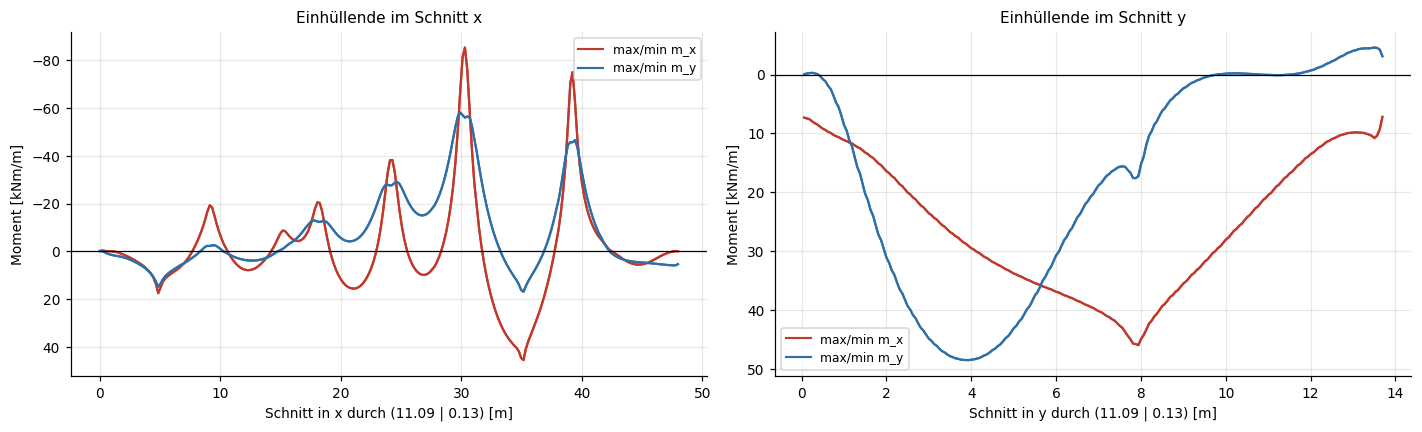

In [ ]:
i_max = int(np.argmax(huellen['m_x']['max']))
p_max = xy[i_max]
grenzen = np.vstack([netz.polygon.min(axis=0), netz.polygon.max(axis=0)])

SCHNITT_X = ((grenzen[0, 0], p_max[1]), (grenzen[1, 0], p_max[1]))
SCHNITT_Y = ((p_max[0], grenzen[0, 1]), (p_max[0], grenzen[1, 1]))

fig, achsen = plt.subplots(1, 2, figsize=(13, 4))
for ax, (a, b), richtung in ((achsen[0], SCHNITT_X, 'x'), (achsen[1], SCHNITT_Y, 'y')):
    for komponente, farbe in (('m_x', '#c0392b'), ('m_y', '#2f6fa8')):
        laenge, oben_ = plate.entlang(xy, huellen[komponente]['max'], a, b, n=250, netz=netz)
        _, unten_ = plate.entlang(xy, huellen[komponente]['min'], a, b, n=250, netz=netz)
        ax.fill_between(laenge, unten_, oben_, color=farbe, alpha=0.18)
        ax.plot(laenge, oben_, color=farbe, lw=1.4, label=f'max/min {komponente}')
        ax.plot(laenge, unten_, color=farbe, lw=1.4)
    ax.axhline(0, color='k', lw=0.8)
    ax.invert_yaxis()
    ax.set_xlabel(f'Schnitt in {richtung} durch ({p_max[0]:.2f} | {p_max[1]:.2f}) [m]')
    ax.set_ylabel('Moment [kNm/m]'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    ax.set_title(f'Einhüllende im Schnitt {richtung}')
plt.tight_layout(); plt.show()

## 10. Ungünstige Laststellung

Bei mehreren Feldern erzeugt die Nutzlast in einem Feld im Nachbarfeld ein
Moment mit umgekehrtem Vorzeichen. Wer alle Felder gleichzeitig belastet,
findet weder das größte Feld- noch das größte Stützmoment.

Weil das System linear ist, braucht es dafür kein Schachbrettmuster: jede
gezeichnete Lastfläche wird einzeln gelöst, und an jeder Stelle werden die
Beiträge mit dem ungünstigen Vorzeichen zusammengenommen. Das ist die
Auswertung über Einflussflächen und liefert die wirkliche Einhüllende — nicht
zwei geratene Lastbilder.

Ständige Einwirkungen haben diese Wahl nicht; sie werden mit γ = 1,35 oder
1,0 angesetzt, je nachdem, ob sie an der Stelle ungünstig oder günstig wirken.

In [ ]:
einzelflaechen = {}
for fall in modell.lastfaelle:
    if fall.get('art') != 'G':
        einzelflaechen.update(plate.felder_je_lastflaeche(modell, netz, fall['id']))

if len(einzelflaechen) < 2:
    print('Weniger als zwei veränderliche Lastflächen — die Laststellung ist eindeutig, '
          'dieser Abschnitt bleibt ohne Wirkung.')
    guenstig = None
else:
    staendig = {k: felder[k] for k in felder
                if k == 'EG' or modell.lastfall(k).get('art') == 'G'}
    t0 = time.time()
    loes_e, vek_e = loeser.loese_alle({**staendig, **einzelflaechen})
    print(f'{len(loes_e)} Einzelfelder gelöst in {time.time() - t0:.2f} s: {list(loes_e)}')

    beitraege = {k: plate.schnittgroessen(u, netz, E, nu) for k, u in loes_e.items()}
    guenstig = {komponente: plate.ungünstig({k: v[komponente] for k, v in beitraege.items()},
                                            staendig=set(staendig))
                for komponente in ('m_x', 'm_y', 'm_xy')}

    for komponente in ('m_x', 'm_y'):
        alt, neu = huellen[komponente], guenstig[komponente]
        print(f"{komponente}: alle Felder belastet {np.nanmax(alt['max']):7.2f} / "
              f"{np.nanmin(alt['min']):7.2f}   →   ungünstig gestellt "
              f"{np.nanmax(neu['max']):7.2f} / {np.nanmin(neu['min']):7.2f} kNm/m")

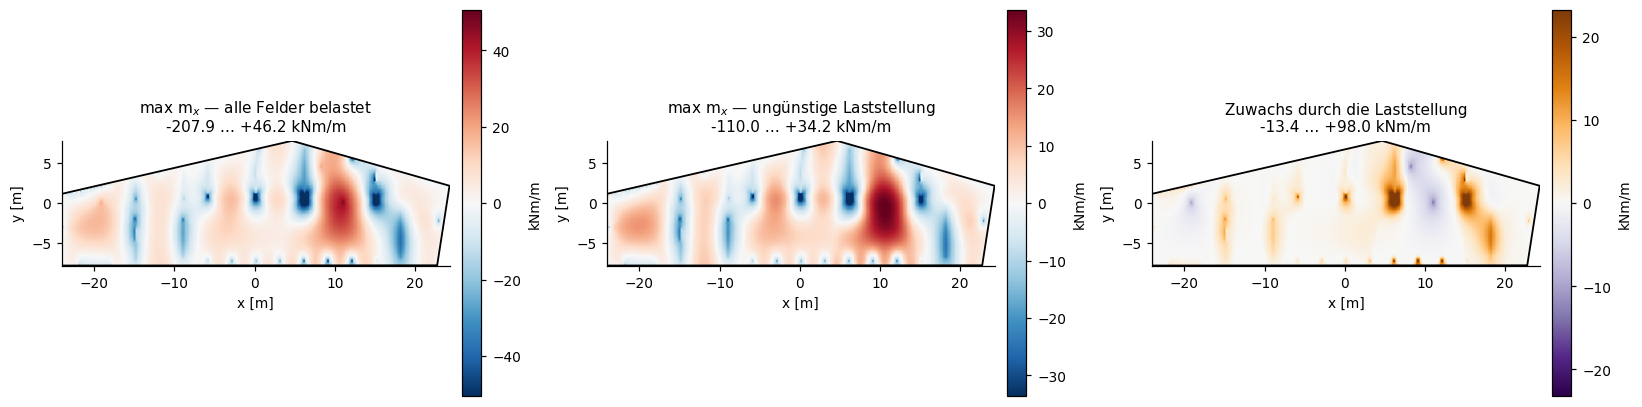

Die Einhüllenden für die Bemessung enthalten jetzt die ungünstige Laststellung.


In [ ]:
if guenstig is not None:
    fig, achsen = plt.subplots(1, 3, figsize=(15, 4.3))
    zeichnen.karte(achsen[0], xy, huellen['m_x']['max'], netz,
                   titel='max m$_x$ — alle Felder belastet', einheit='kNm/m')
    zeichnen.karte(achsen[1], xy, guenstig['m_x']['max'], netz,
                   titel='max m$_x$ — ungünstige Laststellung', einheit='kNm/m')
    zeichnen.karte(achsen[2], xy, guenstig['m_x']['max'] - huellen['m_x']['max'], netz,
                   titel='Zuwachs durch die Laststellung', einheit='kNm/m', cmap='PuOr_r')
    plt.tight_layout(); plt.show()

    # Für die Bemessung wird die ungünstigere der beiden Auswertungen genommen.
    for komponente in ('m_x', 'm_y', 'm_xy'):
        huellen[komponente]['max'] = np.maximum(huellen[komponente]['max'],
                                                guenstig[komponente]['max'])
        huellen[komponente]['min'] = np.minimum(huellen[komponente]['min'],
                                                guenstig[komponente]['min'])
    print('Die Einhüllenden für die Bemessung enthalten jetzt die ungünstige Laststellung.')

## 11. Querkraft

Zwei Wege, und der zweite ist der belastbare:

* **im Feld** aus dem Gleichgewicht der Schnittgrößen, v_x = ∂m_x/∂x +
  ∂m_xy/∂y. Das ist der Weg der Plattenprogramme; er nutzt die Momente, die
  zuverlässigste Größe des Modells.
* **am Auflager** aus der Auflagerkraft je Meter Lagerlinie. Genau dort ist
  v_Ed nachzuweisen, und dort steht der Wert exakt zur Verfügung.

Die Spitzen im Feldbild an den Lagerlinien und an der Stütze sind
Singularitäten des Modells — das Lager hält nur die Unterkante — und keine
Bemessungswerte.

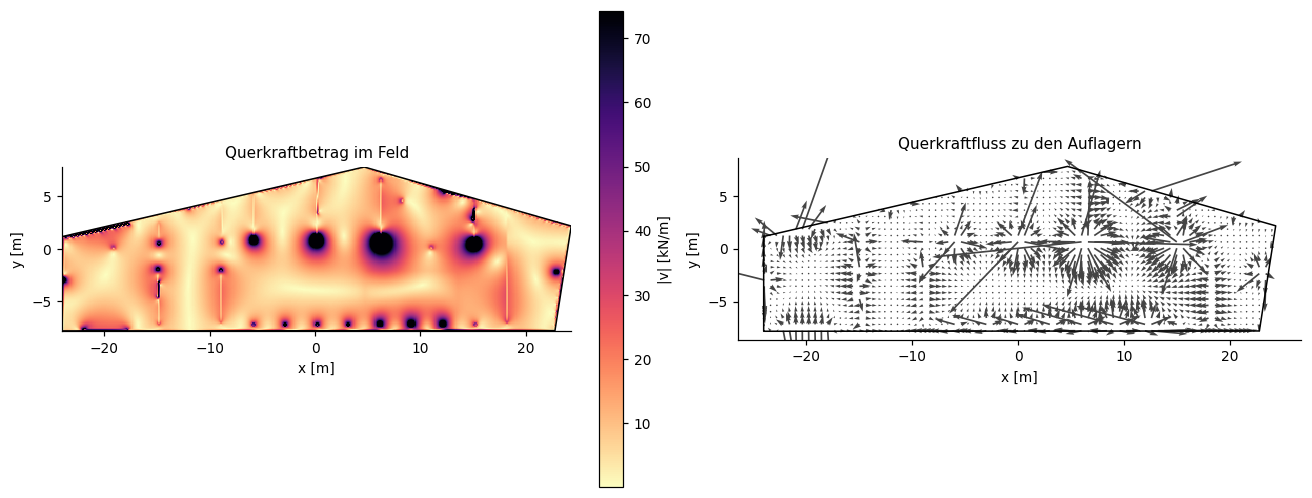

In [ ]:
v_feld = plate.querkraefte_aus_momenten(s, netz)

fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6))
bild = achsen[0].pcolormesh(v_feld['X'], v_feld['Y'], v_feld['v_res'],
                            cmap='magma_r', shading='nearest',
                            vmax=float(np.nanpercentile(v_feld['v_res'], 98)))
plt.colorbar(bild, ax=achsen[0], fraction=0.046, label='|v| [kN/m]')
achsen[0].plot(*np.vstack([netz.polygon, netz.polygon[:1]]).T, 'k-', lw=1)
achsen[0].set_aspect('equal'); achsen[0].set_title('Querkraftbetrag im Feld')
achsen[0].set_xlabel('x [m]'); achsen[0].set_ylabel('y [m]')

schritt = max(1, int(round(0.6 / netz.groesse)))
achsen[1].quiver(v_feld['X'][::schritt, ::schritt], v_feld['Y'][::schritt, ::schritt],
                 v_feld['v_x'][::schritt, ::schritt], v_feld['v_y'][::schritt, ::schritt],
                 color='#444444', scale=None, width=0.003)
achsen[1].plot(*np.vstack([netz.polygon, netz.polygon[:1]]).T, 'k-', lw=1)
achsen[1].set_aspect('equal'); achsen[1].set_title('Querkraftfluss zu den Auflagern')
achsen[1].set_xlabel('x [m]'); achsen[1].set_ylabel('y [m]')
plt.tight_layout(); plt.show()

## 12. Auflagerkräfte

R = K·u − f, ausgewertet für die maßgebende Kombination und zusammengefasst je
gezeichnetem Lager. Die Kraft je Meter ist der Wert, mit dem die Wand darunter
bemessen wird — und zugleich der Bemessungswert der Querkraft am
Auflagerrand.

Ein negativer Wert heißt **abhebende Auflagerkraft**. Das ist kein Rechenfehler:
an einspringenden Ecken und in kurzen Randstreifen hebelt die Nachbarfläche
die Platte hoch. Eine Wand kann das aufnehmen, ein aufgelegtes Fertigteil
nicht — und in beiden Fällen gehört es in die Bewehrungsführung.

Lager  Typ      l [m]   R_z [kN]  R_z/l [kN/m]
------------------------------------------------
A1     linie    12.63      144.7         11.46
A2     linie    10.73      314.6         29.31
A3     linie     5.85      687.8        117.57
A4     linie     4.03      448.8        111.23
A5     linie    12.79       96.5          7.54
A6     linie     5.79      382.1         65.97
A7     linie     4.44      246.0         55.45
A8     linie     3.90       90.7         23.22
A9     linie     2.05      130.2         63.44
A10    linie     6.31      196.5         31.14
A11    linie     4.35       78.8         18.12
A12    linie     6.20      158.7         25.60
A13    linie     5.18      308.3         59.52
A14    linie     5.08      287.1         56.54
A15    punkt        –        0.0             –
A16    punkt        –       35.7             –
A17    punkt        –      165.8             –
A18    punkt        –      173.2             –
A19    punkt        –       85.0             –
A20    punk

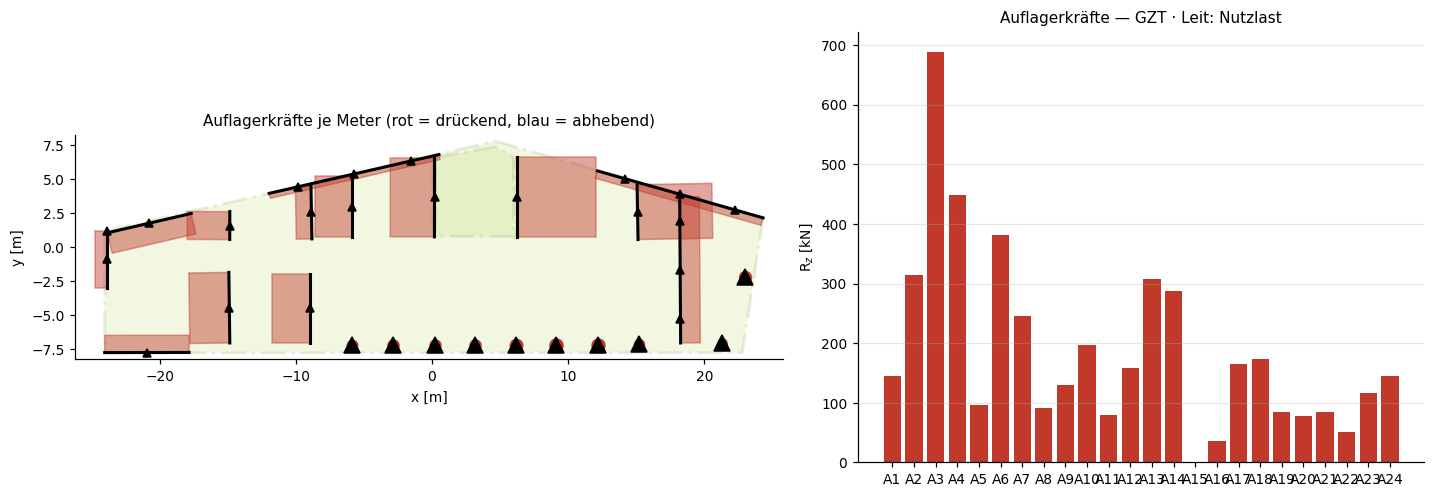

In [ ]:
u_d, f_d = verschiebungen[name], lastvektoren[name]
R = loeser.auflagerkraefte(u_d, f_d)
bilanz = plate.auflagerbilanz(modell, netz, R)

print(f"{'Lager':6s} {'Typ':6s} {'l [m]':>7s} {'R_z [kN]':>10s} {'R_z/l [kN/m]':>13s}")
print('-' * 48)
for eintrag in bilanz:
    laenge = f"{eintrag['laenge_m']:7.2f}" if eintrag['laenge_m'] else '      –'
    je_m = f"{eintrag['R_je_m_kNm']:13.2f}" if eintrag['laenge_m'] else '            –'
    print(f"{eintrag['id']:6s} {eintrag['typ']:6s} {laenge} {eintrag['R_z_kN']:10.1f} {je_m}")
print('-' * 48)
print(f"{'Summe':6s} {'':6s} {'':7s} {sum(e['R_z_kN'] for e in bilanz):10.1f}   "
      f"(Last {-f_d.reshape(-1, 3)[:, 2].sum():.1f} kN)")

fig, achsen = plt.subplots(1, 2, figsize=(13, 4.6),
                           gridspec_kw={'width_ratios': [1.25, 1]})
zeichnen.plan(achsen[0], modell, lasten=False, positionen=False, beschriften=False)
grenze = max(abs(e['R_je_m_kNm']) for e in bilanz if e['laenge_m']) or 1.0
skala = 0.12 * max(netz.polygon.max(axis=0) - netz.polygon.min(axis=0)) / grenze
for lager, eintrag in zip(modell.auflager, bilanz):
    if lager['typ'] != 'linie':
        achsen[0].plot(*np.asarray(lager['p'], dtype=float), 'o', color='#c0392b',
                       ms=6 + 10 * abs(eintrag['R_z_kN']) / max(abs(b['R_z_kN']) for b in bilanz))
        continue
    p = np.asarray(lager['polylinie'], dtype=float)
    richtung = p[-1] - p[0]
    n = np.array([-richtung[1], richtung[0]]) / max(np.linalg.norm(richtung), 1e-9)
    versatz = n * eintrag['R_je_m_kNm'] * skala
    achsen[0].fill(np.r_[p[:, 0], (p + versatz)[::-1, 0]],
                   np.r_[p[:, 1], (p + versatz)[::-1, 1]],
                   color='#c0392b' if eintrag['R_je_m_kNm'] > 0 else '#2f6fa8', alpha=0.45)
achsen[0].set_title('Auflagerkräfte je Meter (rot = drückend, blau = abhebend)')

namen = [e['id'] for e in bilanz]
achsen[1].bar(namen, [e['R_z_kN'] for e in bilanz],
              color=['#c0392b' if e['R_z_kN'] > 0 else '#2f6fa8' for e in bilanz])
achsen[1].set_ylabel('R$_z$ [kN]'); achsen[1].grid(axis='y', alpha=0.3)
achsen[1].set_title(f'Auflagerkräfte — {name}')
plt.tight_layout(); plt.show()

## 13. Die Decke als Scheibe — Wind und Schiefstellung

Bis hierhin war die Decke eine Platte: sie trug senkrecht zu ihrer Ebene. Sie
hat aber eine zweite Aufgabe. In ihrer Ebene ist sie eine **Scheibe**, die die
Windlasten der Fassade sammelt und auf die aussteifenden Wände verteilt. Diese
Aufgabe wird in der Vorbemessung gern übersprungen — sie entscheidet aber
darüber, ob die Randbewehrung reicht und ob der Schub zwischen zwei weit
auseinanderstehenden Wänden aufgenommen wird.

**Zwei Einwirkungen, die verschieden angreifen:**

| | Wind | Schiefstellung |
|---|---|---|
| Ursache | Druck und Sog auf der Fassade | unvermeidliche Lotabweichung, EC2 5.2 |
| Größe | q_p·c_pe·Einzugshöhe | θ_i·N mit θ_i = θ₀·α_h·α_m |
| Angriff | Linienlast am Deckenrand | Flächenlast über die ganze Decke |
| wächst mit | Fassadenfläche | Vertikallast |

Bei gedrungenen, schwer belasteten Gebäuden überholt die Schiefstellung den
Wind. Sie ist keine Formalie, sondern oft die maßgebende Horizontallast — und
sie wirkt in der Scheibe anders, weil sie über die Fläche verteilt angreift
statt am Rand.

Der Winddruck wirkt immer senkrecht auf die Wand, nicht in Windrichtung: bei
rechteckigem Grundriss ist das dasselbe, bei einem gefalteten nicht — und dort
entstehen die Torsionsmomente, die man in der Deckenscheibe sehen will.

Windzone 2, h = 12.0 m (Binnenland) → q_p = 0.80 kN/m²
Einzugshöhe der Decke: 3.20 m (halbe Geschosshöhe darüber und darunter)

w_x+: 2 belastete Randkanten, ΣF = (  31.05 |   -1.97) kN
w_x-: 2 belastete Randkanten, ΣF = ( -31.81 |    3.16) kN
w_y+: 3 belastete Randkanten, ΣF = (  -1.34 |  157.78) kN
w_y-: 3 belastete Randkanten, ΣF = (   2.09 | -158.96) kN


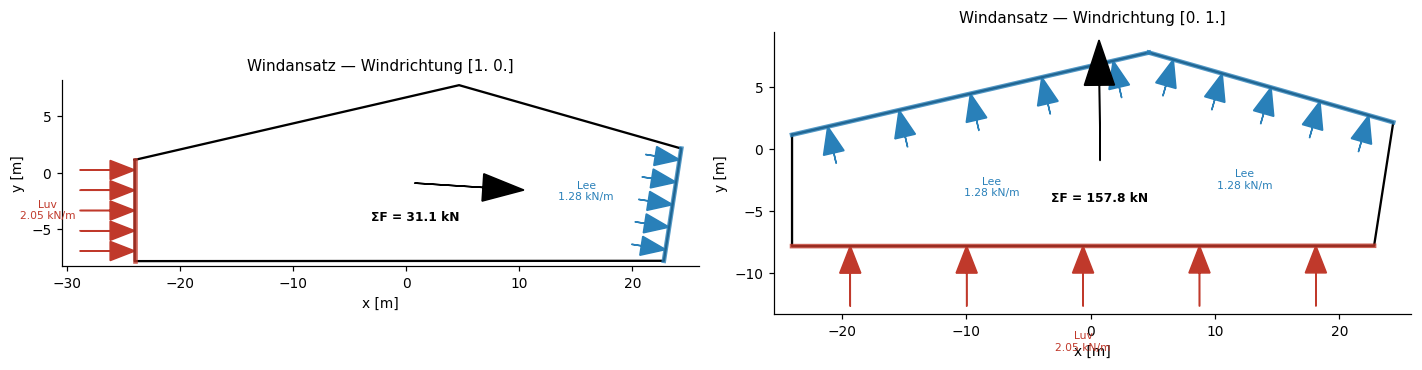

In [ ]:
q_p = scheibe.staudruck_kNm2(WINDZONE, GEBAEUDEHOEHE)
print(f'Windzone {WINDZONE}, h = {GEBAEUDEHOEHE} m (Binnenland) → q_p = {q_p:.2f} kN/m²')
print(f'Einzugshöhe der Decke: {GESCHOSSHOEHE:.2f} m '
      f'(halbe Geschosshöhe darüber und darunter)\n')

WINDRICHTUNGEN = {'w_x+': (1, 0), 'w_x-': (-1, 0), 'w_y+': (0, 1), 'w_y-': (0, -1)}
windlasten = {kennung: scheibe.windkanten(netz, richtung, q_p, GESCHOSSHOEHE)
              for kennung, richtung in WINDRICHTUNGEN.items()}

for kennung, lasten in windlasten.items():
    F = scheibe.gesamtkraft(lasten)
    print(f'{kennung}: {len(lasten)} belastete Randkanten, ΣF = '
          f'({F[0]:7.2f} | {F[1]:7.2f}) kN')

fig, achsen = plt.subplots(1, 2, figsize=(13, 4.8))
zeichnen.windbild(achsen[0], modell, netz, windlasten['w_x+'], (1, 0))
zeichnen.windbild(achsen[1], modell, netz, windlasten['w_y+'], (0, 1))
plt.tight_layout(); plt.show()

In [ ]:
# Schiefstellung: sie greift an der Vertikallast an, also am Bemessungswert
N_Ed = abs(float(lastvektoren[name].reshape(-1, 3)[:, 2].sum()))
imp = scheibe.imperfektion(N_Ed * (1 + GESCHOSSE_UEBER), (1, 0),
                           GEBAEUDEHOEHE, GESCHOSSE_UEBER + 1)

print(f"θ_i = θ₀·α_h·α_m = 1/200 · {imp['alpha_h']:.3f} · {imp['alpha_m']:.3f} "
      f"= 1/{1/imp['theta_i']:.0f}")
print(f"N_Ed dieser Decke      : {N_Ed:8.1f} kN")
print(f"N_Ed mit {GESCHOSSE_UEBER} Geschossen darüber: {N_Ed * (1 + GESCHOSSE_UEBER):8.1f} kN")
print(f"H_i aus Schiefstellung : {imp['H_kN']:8.1f} kN")
print(f"H aus Wind (x)         : {abs(scheibe.gesamtkraft(windlasten['w_x+'])[0]):8.1f} kN")
print('\nmaßgebend:', 'Schiefstellung' if imp['H_kN'] > abs(scheibe.gesamtkraft(windlasten['w_x+'])[0])
      else 'Wind')

θ_i = θ₀·α_h·α_m = 1/200 · 0.577 · 0.791 = 1/438
N_Ed dieser Decke      :   4504.0 kN
N_Ed mit 3 Geschossen darüber:  18015.8 kN
H_i aus Schiefstellung :     41.1 kN
H aus Wind (x)         :     31.1 kN

maßgebend: Schiefstellung


## 14. Das Scheibensystem

Andere Lager als bei der Platte: gehalten wird u_z an allen Lagerlinien und
zusätzlich **u in Wandrichtung** an den aussteifenden Wänden. Eine Wand ist
eine Scheibe — sie hält in ihrer eigenen Ebene und quer dazu so gut wie nicht.
Wer alle Wände in alle Richtungen festhält, bekommt eine Decke ohne Schub und
ein Ergebnis, das nichts bedeutet.

Weil das Netz dasselbe ist, kostet der zweite Löser nur eine weitere
Zerlegung; die acht Lastfälle danach sind wieder Millisekunden.

In [ ]:
bc_scheibe, bericht = scheibe.randbedingungen(modell, netz)
print('Aussteifende Wände:', ', '.join(bericht['wände']))
print(f"in x gehalten: {bericht['in_x_haltend']} Knoten, "
      f"in y: {bericht['in_y_haltend']}, Senkung: {bericht['senkung_gehalten']}")

t0 = time.time()
loeser_s = Loeser(netz, E, nu, bc_scheibe)
print(f'Scheibensystem aufgestellt und zerlegt: {time.time() - t0:.1f} s')

felder_s = {kennung: scheibe.randlastfeld(netz, lasten)
            for kennung, lasten in windlasten.items()}
for kennung, richtung in (('imp_x+', (1, 0)), ('imp_x-', (-1, 0)),
                          ('imp_y+', (0, 1)), ('imp_y-', (0, -1))):
    felder_s[kennung] = scheibe.imperfektionsfeld(netz, imp['H_kN'], richtung)

loes_s, vek_s = loeser_s.loese_alle(felder_s)
print(f'{len(felder_s)} Scheibenlastfälle gelöst\n')

for kennung in felder_s:
    p = loeser_s.probe(loes_s[kennung], vek_s[kennung])
    print(f"{kennung:7s} Last ({p['last_kN'][0]:7.2f} | {p['last_kN'][1]:7.2f}) kN   "
          f"Auflager ({p['auflager_kN'][0]:7.2f} | {p['auflager_kN'][1]:7.2f})   "
          f"Abweichung {p['abweichung_rel']:.0e}")

Aussteifende Wände: A1, A2, A3, A4, A5, A6, A7, A8, A9, A10, A11, A12, A13, A14
in x gehalten: 1479 Knoten, in y: 1752, Senkung: 1086
Scheibensystem aufgestellt und zerlegt: 179.0 s
8 Scheibenlastfälle gelöst

w_x+    Last (  31.02 |   -1.97) kN   Auflager ( -31.02 |    1.97)   Abweichung 4e-13
w_x-    Last ( -31.77 |    3.16) kN   Auflager (  31.77 |   -3.16)   Abweichung 4e-13
w_y+    Last (  -1.34 |  157.58) kN   Auflager (   1.34 | -157.58)   Abweichung 1e-13
w_y-    Last (   2.09 | -158.77) kN   Auflager (  -2.09 |  158.77)   Abweichung 8e-14
imp_x+  Last (  41.06 |    0.00) kN   Auflager ( -41.06 |   -0.00)   Abweichung 3e-12
imp_x-  Last ( -41.06 |    0.00) kN   Auflager (  41.06 |    0.00)   Abweichung 3e-12
imp_y+  Last (   0.00 |   41.06) kN   Auflager (  -0.00 |  -41.06)   Abweichung 3e-12
imp_y-  Last (   0.00 |  -41.06) kN   Auflager (   0.00 |   41.06)   Abweichung 3e-12


### Kombination der Horizontallasten

Wind ist eine veränderliche Einwirkung und bekommt γ_Q = 1,5 (als
Leiteinwirkung) beziehungsweise γ_Q·ψ₀ = 0,9. Die Schiefstellung ist keine
Einwirkung, sondern eine geometrische Ersatzlast: sie steckt schon im
Bemessungswert der Vertikallast, aus dem sie berechnet wurde, und wird deshalb
mit 1,0 überlagert.

Gerechnet wird die ungünstigste der vier Windrichtungen, jeweils mit der
gleichgerichteten Schiefstellung.

In [ ]:
scheibe.registriere_lastfall(modell, 'w', 'Wind', art='W', gamma=1.5, psi0=0.6)
kombis = plate.kombinationen(modell)          # jetzt mit Wind als Lastfall
gamma_w = kombis.get('GZT · Leit: Wind', {}).get('w', 1.5)

paare = {'x+': ('w_x+', 'imp_x+'), 'x-': ('w_x-', 'imp_x-'),
         'y+': ('w_y+', 'imp_y+'), 'y-': ('w_y-', 'imp_y-')}

membran, wandbilanz = {}, {}
for bezeichnung, (wind_id, imp_id) in paare.items():
    u = gamma_w * loes_s[wind_id] + 1.0 * loes_s[imp_id]
    f = gamma_w * vek_s[wind_id] + 1.0 * vek_s[imp_id]
    membran[bezeichnung] = scheibe.membrankraefte(u, netz, E, nu)
    wandbilanz[bezeichnung] = scheibe.wandkraefte(
        modell, netz, loeser_s.auflagerkraefte(u, f))

# Einhüllende der Membrankräfte über die vier Richtungen
n_huelle = {k: plate.einhuellende({b: m[k] for b, m in membran.items()})
            for k in ('n_x', 'n_y', 'n_xy')}
print(f"γ_Q(Wind) = {gamma_w}, Schiefstellung mit 1,0\n")
for k in ('n_x', 'n_y', 'n_xy'):
    print(f"{k:5s} {n_huelle[k]['min'].min():8.2f} … {n_huelle[k]['max'].max():8.2f} kN/m")

γ_Q(Wind) = 1.5, Schiefstellung mit 1,0

n_x     -10.63 …    11.90 kN/m
n_y     -20.53 …    16.45 kN/m
n_xy    -10.10 …    10.21 kN/m


gezeigt wird die Windrichtung mit dem größten Scheibenschub: y+


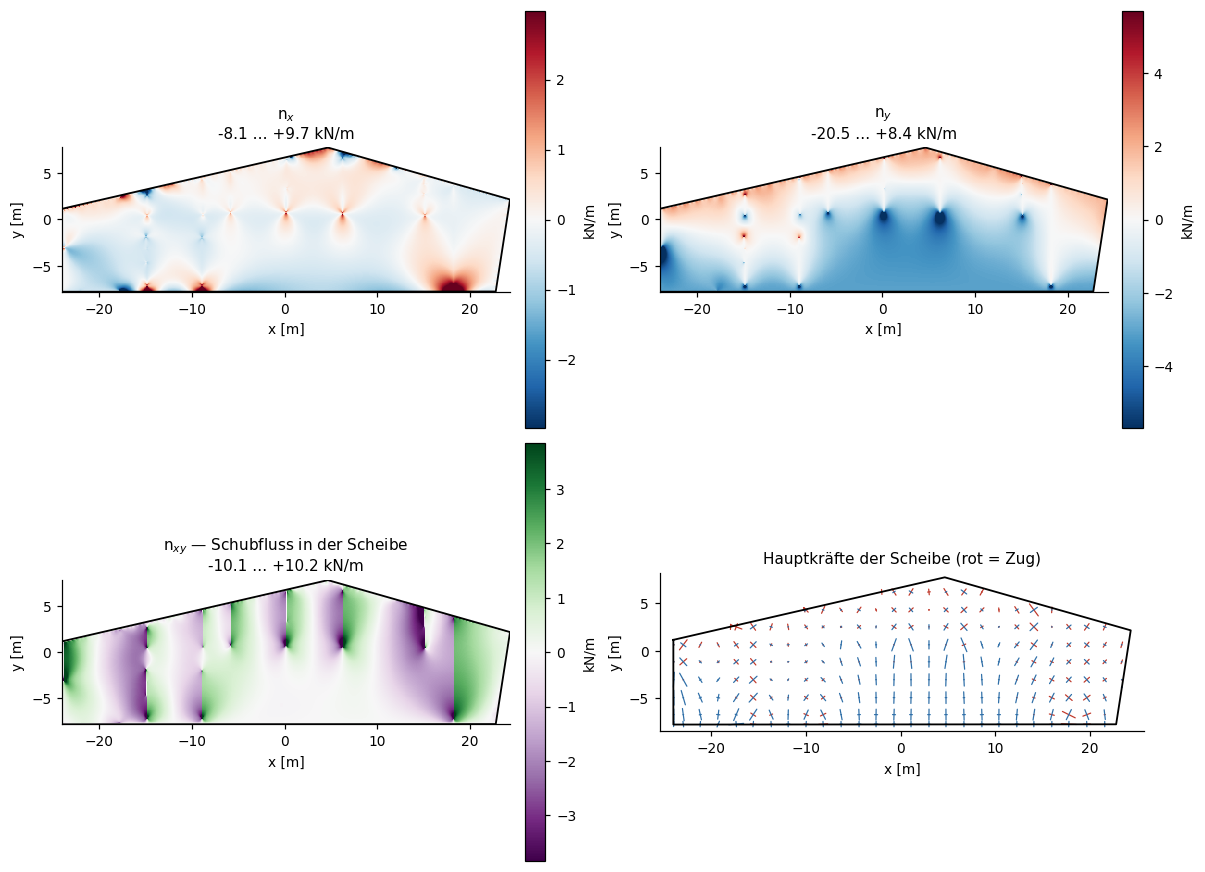

In [ ]:
massgebende_richtung = max(paare, key=lambda b: np.abs(membran[b]['n_xy']).max())
m_s = membran[massgebende_richtung]
print('gezeigt wird die Windrichtung mit dem größten Scheibenschub:', massgebende_richtung)

fig, achsen = plt.subplots(2, 2, figsize=(11, 8))
zeichnen.karte(achsen[0, 0], m_s['xy'], m_s['n_x'], netz, titel='n$_x$', einheit='kN/m')
zeichnen.karte(achsen[0, 1], m_s['xy'], m_s['n_y'], netz, titel='n$_y$', einheit='kN/m')
zeichnen.karte(achsen[1, 0], m_s['xy'], m_s['n_xy'], netz,
               titel='n$_{xy}$ — Schubfluss in der Scheibe', einheit='kN/m', cmap='PRGn')
zeichnen.trajektorien(achsen[1, 1], m_s['xy'], m_s['n_1'], m_s['n_2'], m_s['phi'], netz,
                      titel='Hauptkräfte der Scheibe (rot = Zug)')
plt.tight_layout(); plt.show()

### Wandkräfte — das eigentliche Ergebnis

Was jede Wand aufnimmt, ist die Zahl, mit der die Wandscheibe darunter bemessen
wird. Die Summe über alle Wände einer Richtung muss die angesetzte
Horizontallast sein; das ist zugleich die Probe der ganzen Scheibenrechnung.

x+: Σ Wandkräfte   -87.59 kN gegen angesetzte Last    87.59 kN (theoretisch   87.70)
x-: Σ Wandkräfte    88.71 kN gegen angesetzte Last   -88.71 kN (theoretisch  -88.82)
y+: Σ Wandkräfte  -277.44 kN gegen angesetzte Last   277.44 kN (theoretisch  277.78)
y-: Σ Wandkräfte   279.22 kN gegen angesetzte Last  -279.22 kN (theoretisch -279.56)


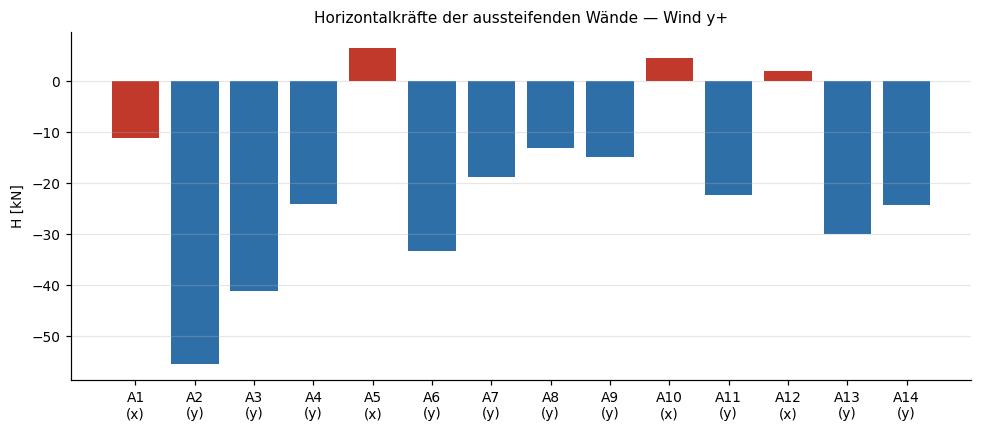


Wand   Achse    l [m]    H [kN]  Schub [kN/m]
A2     y        10.73    -55.50         -5.17
A3     y         5.85    -41.15         -7.03
A6     y         5.79    -33.27         -5.74
A13    y         5.18    -29.97         -5.79
A14    y         5.08    -24.35         -4.79
A4     y         4.03    -24.14         -5.98
A11    y         4.20    -22.28         -5.30
A7     y         4.44    -18.84         -4.25
A9     y         2.05    -14.88         -7.25
A8     y         3.90    -13.06         -3.34
A1     x        12.63    -11.12         -0.88
A5     x        12.79      6.56          0.51
A10    x         6.31      4.57          0.72
A12    x         6.20      2.00          0.32


In [ ]:
for bezeichnung, (wind_id, imp_id) in paare.items():
    achse = 0 if bezeichnung.startswith('x') else 1
    summe = sum(w['H_kN'] for w in wandbilanz[bezeichnung]
                if w['achse'] == ('x' if achse == 0 else 'y'))
    # Verglichen wird mit der *angesetzten* Last aus dem Lastvektor, nicht mit
    # der theoretischen Kantenkraft: der Treppenrand des Rasternetzes nimmt
    # unterwegs ein paar Promille mit, und die gehören in Abschnitt 13, nicht
    # in die Gleichgewichtsprobe.
    last = float((gamma_w * vek_s[wind_id] + vek_s[imp_id]).reshape(-1, 3)[:, achse].sum())
    theorie = gamma_w * scheibe.gesamtkraft(windlasten[wind_id])[achse] + \
        imp['H_kN'] * (1 if bezeichnung.endswith('+') else -1)
    print(f"{bezeichnung}: Σ Wandkräfte {summe:8.2f} kN gegen angesetzte Last {last:8.2f} kN "
          f"(theoretisch {theorie:7.2f})")

fig, ax = plt.subplots(figsize=(9, 4))
waende = wandbilanz[massgebende_richtung]
farben = ['#c0392b' if w['achse'] == 'x' else '#2f6fa8' for w in waende]
ax.bar([f"{w['id']}\n({w['achse']})" for w in waende],
       [w['H_kN'] for w in waende], color=farben)
ax.set_ylabel('H [kN]'); ax.grid(axis='y', alpha=0.3)
ax.set_title(f'Horizontalkräfte der aussteifenden Wände — Wind {massgebende_richtung}')
plt.tight_layout(); plt.show()

print(f"\n{'Wand':6s} {'Achse':6s} {'l [m]':>7s} {'H [kN]':>9s} {'Schub [kN/m]':>13s}")
for w in sorted(waende, key=lambda w: -abs(w['H_kN'])):
    print(f"{w['id']:6s} {w['achse']:6s} {w['laenge_m']:7.2f} {w['H_kN']:9.2f} "
          f"{w['schub_je_m_kNm']:13.2f}")

## 15. Wenn nur ein Kern aussteift

Bisher galt jede Wand als aussteifend. Das ist für einen Wandbau richtig, für
einen Skelettbau nicht: dort steift ein Kern aus, der Rest sind Stützen. Die
Decke muss die Windlast dann über die ganze Gebäudelänge zu diesem Kern
transportieren und wirkt als tiefer Träger, dessen Steg der Deckenspiegel ist.

**Drei Wandscheiben, deren Achsen sich nicht in einem Punkt schneiden** — das
ist die Bedingung, und die dritte Hälfte davon wird regelmäßig übersehen. Zwei
Wände über Eck sehen nach einer soliden Aussteifung aus, aber das Geschoss kann
sich um ihren Schnittpunkt drehen. Im Rechenmodell fällt das nicht als
Fehlermeldung auf, sondern als sechsstellige Membrankraft;
`scheibe.pruefe_aussteifung()` bricht deshalb mit einer Erklärung ab, statt
eine Zahl zu liefern.

Der Vergleich zeigt zweierlei: wie stark die Annahme über die Aussteifung das
Ergebnis bestimmt — stärker als jede Feinheit der Windlastermittlung — und dass
weniger Wände nicht zwangsläufig größere Kräfte bedeuten. Eine kurze Wand
mitten in der Fläche zieht den Schub örtlich zusammen; fällt sie weg, verteilt
er sich gleichmäßiger, dafür über eine größere Länge.

als Kern angenommen: ['A5', 'A1', 'A2'] — alles andere trägt nur senkrecht


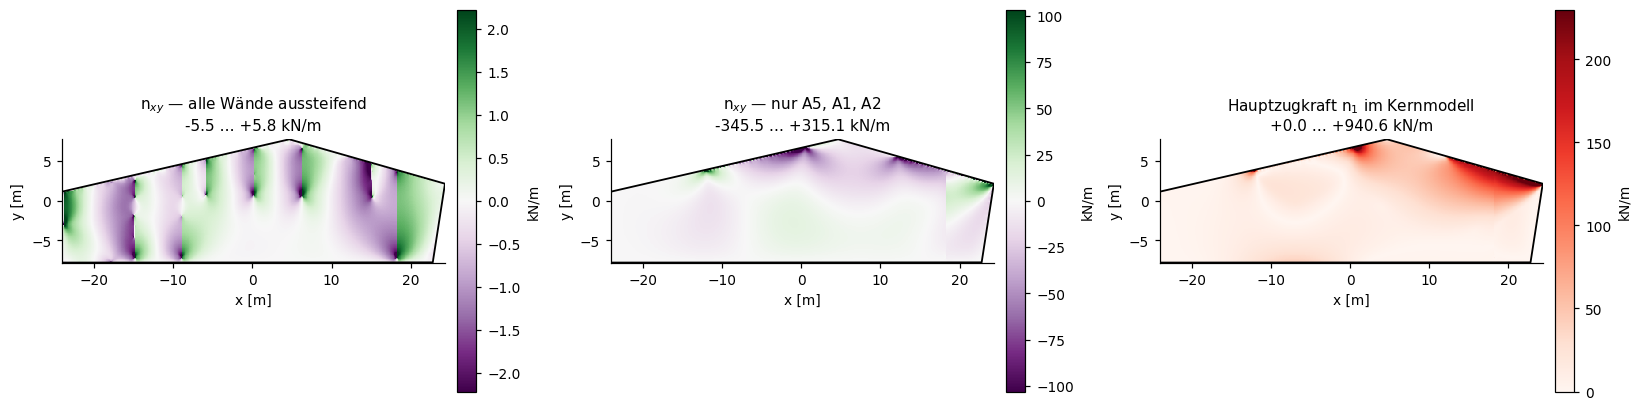

max |n_xy|: alle Wände   5.83 kN/m  →  nur Kern 345.51 kN/m  (59.2-fach)


In [ ]:
# Drei Wände, deren Achsen sich nicht in einem Punkt schneiden — sonst dreht
# sich das Geschoss um diesen Punkt. `pruefe_aussteifung` bricht in dem Fall ab.
waende_alle = scheibe.wandrichtungen(modell)
in_x = [w for w in waende_alle if w['achse'] == 0]
in_y = [w for w in waende_alle if w['achse'] == 1]
in_x = sorted(in_x, key=lambda w: -w['laenge_m'])
in_y = sorted(in_y, key=lambda w: -w['laenge_m'])

KERN = []
if len(in_x) >= 2 and in_y:
    KERN = [in_x[0]['id'], in_x[1]['id'], in_y[0]['id']]
elif in_x and len(in_y) >= 2:
    KERN = [in_x[0]['id'], in_y[0]['id'], in_y[1]['id']]
print('als Kern angenommen:', KERN, '— alles andere trägt nur senkrecht')

if len(KERN) >= 3:
    bc_kern, bericht_kern = scheibe.randbedingungen(modell, netz, aussteifend=KERN)
    loeser_k = Loeser(netz, E, nu, bc_kern)
    u_k = loeser_k.loese(felder_s[paare[massgebende_richtung][0]])
    m_k = scheibe.membrankraefte(u_k, netz, E, nu)
    m_alle = scheibe.membrankraefte(loes_s[paare[massgebende_richtung][0]], netz, E, nu)

    fig, achsen = plt.subplots(1, 3, figsize=(15, 4.3))
    zeichnen.karte(achsen[0], m_alle['xy'], m_alle['n_xy'], netz,
                   titel='n$_{xy}$ — alle Wände aussteifend', einheit='kN/m', cmap='PRGn')
    zeichnen.karte(achsen[1], m_k['xy'], m_k['n_xy'], netz,
                   titel=f"n$_{{xy}}$ — nur {', '.join(KERN)}", einheit='kN/m', cmap='PRGn')
    zeichnen.karte(achsen[2], m_k['xy'], np.abs(m_k['n_1']), netz,
                   titel='Hauptzugkraft n$_1$ im Kernmodell', einheit='kN/m',
                   symmetrisch=False, cmap='Reds')
    plt.tight_layout(); plt.show()

    print(f"max |n_xy|: alle Wände {np.abs(m_alle['n_xy']).max():6.2f} kN/m  →  "
          f"nur Kern {np.abs(m_k['n_xy']).max():6.2f} kN/m  "
          f"({np.abs(m_k['n_xy']).max() / max(np.abs(m_alle['n_xy']).max(), 1e-9):.1f}-fach)")

    # Die Zerlegung dieses Vergleichsmodells belegt bei großen Netzen mehrere
    # Gigabyte und wird danach nicht mehr gebraucht.
    del loeser_k
    import gc; gc.collect()
else:
    print('Zu wenige Wandscheiben für einen sinnvollen Kern — der Vergleich entfällt.')

## 16. Bewehrung der Scheibe

Orthogonale Netzbewehrung für einen ebenen Spannungszustand nach EC2 Anhang F.
Der Schub n_xy wird über eine unter 45° geneigte Betondruckstrebe abgetragen,
deren Umlenkung beide Bewehrungsrichtungen belastet:

    n_sx = n_x + |n_xy| ,  n_sy = n_y + |n_xy| ,  n_c = −2·|n_xy|

**Der Nachweis, den man vergisst, ist der der Druckstrebe.** Die Bewehrung ist
meist unkritisch, die Betonspannung nicht: sie darf ν·f_cd nicht überschreiten.
An einspringenden Ecken und neben Öffnungen wird das eng — und dort hilft mehr
Bewehrung nichts.

Zum Vergleich steht der Ringanker daneben: F_tie = max(l·10 kN/m; 70 kN) nach
EC2 9.10. Er hat mit dem Wind nichts zu tun — er sichert den Zusammenhalt beim
außergewöhnlichen Ereignis —, deckt die Scheibenzugkraft am Rand aber meist
schon ab.

**Und das ist der Regelfall:** die Scheibenbewehrung fällt gegen die
Biegebewehrung kaum ins Gewicht, solange genug Wände mitwirken. Deshalb darf
man den Nachweis meist zusammen mit dem Ringanker abhaken — aber erst,
nachdem man ihn gesehen hat. Maßgebend wird er in genau den Fällen, die
Abschnitt 15 zeigt: wenige Wände, große Entfernungen, einspringende Ecken.

In [ ]:
c = bt.beton(platte['material']['name'])
print(c)

# `m_s['hoehe_m']` statt `h`: die Betonspannung folgt aus der Kraft geteilt durch
# die *wirkliche* Querschnittshöhe, und im Streifen eines Unterzugs ist die
# größer als die Plattendicke. Mit h stünde dort eine zu hohe Ausnutzung —
# ausgerechnet an der Stelle, an der die Scheibe ihren Gurt hat.
scheibenwahl = bt.scheibenbewehrung(n_huelle['n_x']['max'], n_huelle['n_y']['max'],
                                    np.maximum(np.abs(n_huelle['n_xy']['max']),
                                               np.abs(n_huelle['n_xy']['min'])),
                                    c, m_s['hoehe_m'])

fig, achsen = plt.subplots(1, 3, figsize=(15, 4.3))
zeichnen.karte(achsen[0], m_s['xy'], scheibenwahl['a_sx_cm2'], netz,
               titel='a$_{sx}$ aus der Scheibe', einheit='cm²/m',
               symmetrisch=False, cmap='Reds')
zeichnen.karte(achsen[1], m_s['xy'], scheibenwahl['a_sy_cm2'], netz,
               titel='a$_{sy}$ aus der Scheibe', einheit='cm²/m',
               symmetrisch=False, cmap='Reds')
zeichnen.karte(achsen[2], m_s['xy'], scheibenwahl['ausnutzung_druckstrebe'], netz,
               titel='Druckstrebe σ_c / (ν·f$_{cd}$)', einheit='–',
               symmetrisch=False, cmap='YlOrBr')
plt.tight_layout(); plt.show()

umfang = float(np.sum(np.linalg.norm(np.diff(np.vstack([netz.polygon, netz.polygon[:1]]),
                                             axis=0), axis=1)))
laenge = float(max(netz.polygon.max(axis=0) - netz.polygon.min(axis=0)))
print(f"a_sx max {scheibenwahl['a_sx_cm2'].max():.2f} cm²/m, "
      f"a_sy max {scheibenwahl['a_sy_cm2'].max():.2f} cm²/m")
print(f"Druckstrebe: max {scheibenwahl['ausnutzung_druckstrebe'].max():.3f} "
      f"(zulässig σ_c = {scheibenwahl['sigma_c_zul_MNm2']:.2f} MN/m²)")
print(f"Ringanker nach EC2 9.10: F_tie = {bt.ringanker_kN(laenge):.0f} kN → "
      f"{bt.ringanker_kN(laenge) / bt.B500B.f_yd * 1e4:.2f} cm² am Rand, "
      f"Umfang {umfang:.1f} m")

## 17. Biegebemessung

Jetzt kommt alles zusammen: die Momente der Platte, die Normalkräfte der
Scheibe, die Baustoffe aus dem Plan.

**Drei Dinge, die die Bewehrungsmenge bestimmen und leicht falsch gemacht
werden:**

1. **Die beiden Lagen haben verschiedene Nutzhöhen.** Sie liegen übereinander,
   nicht nebeneinander — die innere hat einen Stabdurchmesser weniger Hebel.
   Bei 22 cm Dicke und Ø 10 sind das 5 % Unterschied.
2. **Das Drillmoment gehört auf beide Richtungen.** Wood und Armer:
   m_x* = m_x + |m_xy| unten, m_x* = m_x − |m_xy| oben, mit Umlegung, falls
   eine Richtung dabei negativ würde.
3. **Die Normalkraft der Scheibe wirkt mit.** Zug vergrößert die Bewehrung,
   Druck verkleinert sie. Bemessen wird auf das Moment um die Zugbewehrung,
   M_Eds = M_Ed − N_Ed·z_s1, und die Normalkraft danach wieder abgezogen.

Die Bemessung selbst läuft dimensionslos über den Spannungsblock
(λ = 0,8, η = 1,0): μ_Eds → ζ = 1 − √(1 − 2μ) → a_s. Wer die Tabellenwerte
gewohnt ist, findet ω = ζ und ξ = ζ/0,8 in der Ausgabe wieder.

In [ ]:
c_nom = bt.betondeckung_mm(EXPOSITION, DURCHMESSER_MM)
d_x, d_y = bt.nutzhoehen(h, c_nom, DURCHMESSER_MM)
a_s_min = bt.mindestbewehrung_cm2(h, d_x, c)
a_s_max = bt.hoechstbewehrung_cm2(h)

print(f'{c}')
print(f'Expositionsklasse {EXPOSITION} → c_nom = {c_nom:.0f} mm bei Ø {DURCHMESSER_MM}')
print(f'Nutzhöhen: d_x = {d_x*100:.1f} cm (äußere Lage), d_y = {d_y*100:.1f} cm (innere)')
print(f'Mindestbewehrung {a_s_min:.2f} cm²/m, Höchstbewehrung {a_s_max:.1f} cm²/m')
print(f'größter Stababstand: Hauptrichtung {bt.hoechstabstand_mm(h):.0f} mm, '
      f'quer {bt.hoechstabstand_mm(h, "quer"):.0f} mm')

# Wood-Armer je GZT-Kombination, dann einhüllen: max(m_x) und max(m_xy) müssen
# nicht aus derselben Kombination stammen.
wood = {bezeichnung: plate.bemessungsmomente(v['m_x'], v['m_y'], v['m_xy'])
        for bezeichnung, v in gzt.items()}
# dazu die konservative Auswertung der Einhüllenden (enthält die Laststellung)
wood['Einhüllende'] = plate.bemessungsmomente(huellen['m_x']['max'], huellen['m_y']['max'],
                                              huellen['m_xy']['max'])
wood['Einhüllende oben'] = plate.bemessungsmomente(huellen['m_x']['min'], huellen['m_y']['min'],
                                                   huellen['m_xy']['min'])

bemessungsmoment = {lage: plate.einhuellende({k: v[lage] for k, v in wood.items()})['max']
                    for lage in ('m_x_unten', 'm_y_unten', 'm_x_oben', 'm_y_oben')}

assert np.allclose(m_s['xy'], xy), 'Element-Reihenfolge von Platte und Scheibe weicht ab'
n_zug = {'x': np.maximum(n_huelle['n_x']['max'], 0.0) / 2.0,
         'y': np.maximum(n_huelle['n_y']['max'], 0.0) / 2.0}
print(f"\nScheibenzug je Lage: n_x/2 bis {n_zug['x'].max():.1f} kN/m, "
      f"n_y/2 bis {n_zug['y'].max():.1f} kN/m")

C25/30: f_ck = 25, f_cd = 14.17, f_ctm = 2.56 MN/m²
Expositionsklasse XC1 → c_nom = 20 mm bei Ø 10
Nutzhöhen: d_x = 17.5 cm (äußere Lage), d_y = 16.5 cm (innere)
Mindestbewehrung 2.33 cm²/m, Höchstbewehrung 80.0 cm²/m
größter Stababstand: Hauptrichtung 250 mm, quer 400 mm

Scheibenzug je Lage: n_x/2 bis 6.0 kN/m, n_y/2 bis 8.2 kN/m


In [ ]:
LAGEN_BESCHREIBUNG = [
    ('a_sx unten', 'm_x_unten', d_x, n_zug['x']),
    ('a_sy unten', 'm_y_unten', d_y, n_zug['y']),
    ('a_sx oben',  'm_x_oben',  d_x, n_zug['x']),
    ('a_sy oben',  'm_y_oben',  d_y, n_zug['y']),
]

bewehrung = {}
print(f"{'Lage':12s} {'m_Ed max':>10s} {'μ max':>7s} {'a_s max':>9s} "
      f"{'a_s 99,5 %':>11s} {'auf a_s,min':>12s}")
print('-' * 68)
for bezeichnung, schluessel, d_lage, n_lage in LAGEN_BESCHREIBUNG:
    m = bemessungsmoment[schluessel]
    ergebnis_lage = bt.biegebemessung(m, d_lage, c, h=h, n_Ed=n_lage)
    a_s = np.maximum(ergebnis_lage['a_s_cm2'], a_s_min)
    # Der Größtwert steht an einer Singularität (Wandende, einspringende Ecke)
    # und wächst mit jeder Netzverfeinerung. Das 99,5-%-Perzentil ist der Wert,
    # mit dem man die Fläche bewehrt; die Spitze wird örtlich zugelegt.
    # `plate.hoechstwert()` überall dort, wo NaN stehen kann: im Balkenstreifen
    # ist die Platte nicht bemessen, und ein einziges NaN machte aus jedem
    # Perzentil und jedem Größtwert dieser Tabelle ebenfalls NaN.
    bewehrung[bezeichnung] = {'a_s': a_s, 'm': m, 'd': d_lage,
                              'flaeche_cm2': plate.hoechstwert(a_s, 99.5),
                              'roh': ergebnis_lage['a_s_cm2'], **ergebnis_lage}
    anteil_min = 100 * np.nanmean(ergebnis_lage['a_s_cm2'] < a_s_min)
    print(f'{bezeichnung:12s} {plate.hoechstwert(m):10.1f} '
          f'{plate.hoechstwert(ergebnis_lage["mu"]):7.3f} '
          f'{plate.hoechstwert(a_s):9.2f} {bewehrung[bezeichnung]["flaeche_cm2"]:11.2f} '
          f'{anteil_min:11.0f} %')
    if ergebnis_lage['hinweis']:
        print(f'   ! {ergebnis_lage["hinweis"]}')
print('\na_s max steht an einer Singularität (Wandende, einspringende Ecke) und '
      'wächst mit\njeder Netzverfeinerung — bewehrt wird die Fläche nach der '
      'Spalte 99,5 %, die Spitze örtlich.')

fig, achsen = plt.subplots(2, 2, figsize=(11, 8))
for ax, (bezeichnung, *_rest) in zip(achsen.ravel(), LAGEN_BESCHREIBUNG):
    zeichnen.karte(ax, xy, bewehrung[bezeichnung]['a_s'], netz,
                   titel=f'{bezeichnung} (erforderlich, ≥ a$_{{s,min}}$)',
                   einheit='cm²/m', symmetrisch=False, cmap='Reds')
plt.tight_layout(); plt.show()

### Von der erforderlichen zur gelegten Bewehrung

Der Bedarf ist stetig, die Ausführung nicht: gelegt wird eine Matte, dazu
Zulagen. Die Stufenkarte ist deshalb näher am Bewehrungsplan als jede
Verlaufskarte — sie beantwortet die Frage, die auf der Baustelle gestellt
wird: *was liegt hier?*

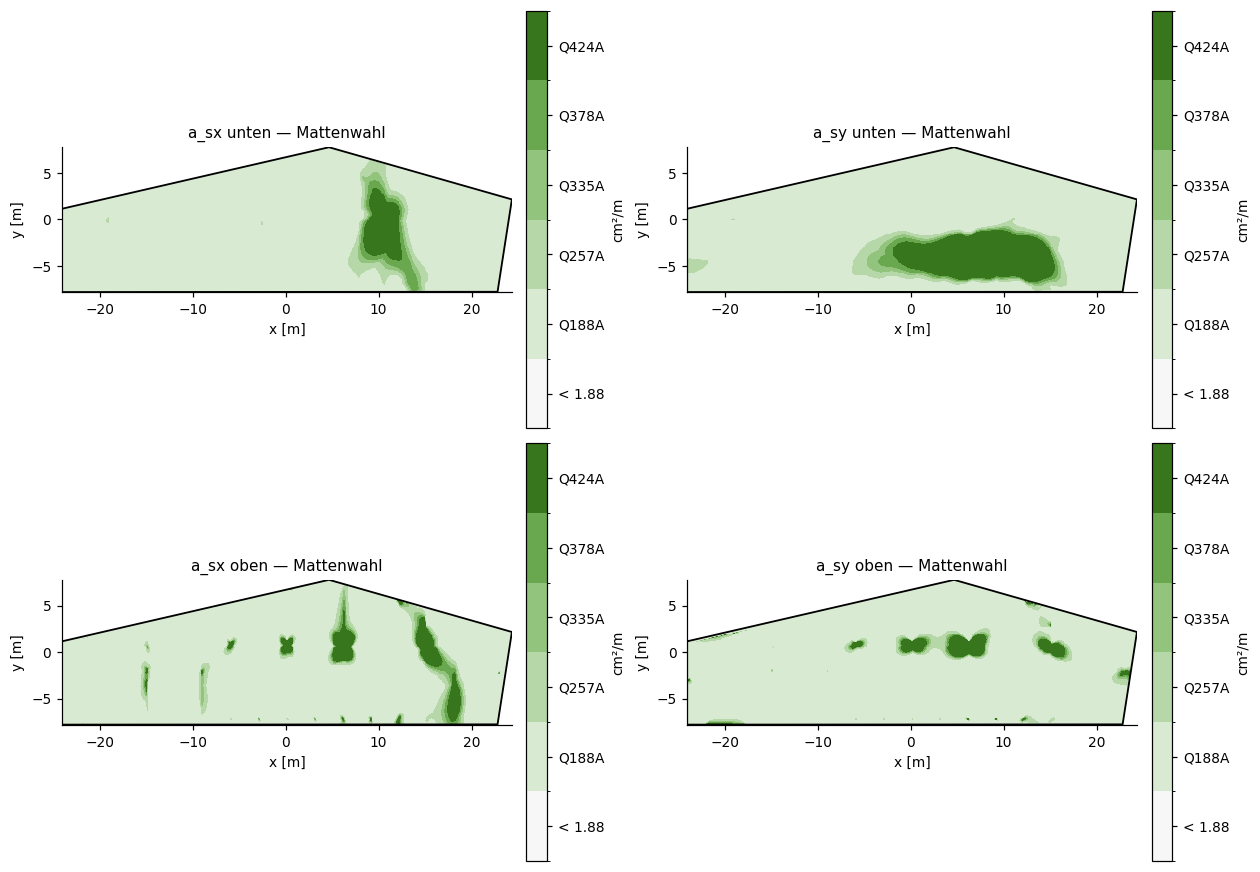

Lage          a_s,erf max  gewählt
a_sx unten           5.77  Q636A (6.36 cm²/m) oder Ø14/250 (6.16 cm²/m)
a_sy unten           9.17  Q636A (6.36 cm²/m) oder Ø16/200 (10.05 cm²/m)
a_sx oben            8.86  Q636A (6.36 cm²/m) oder Ø12/125 (9.05 cm²/m)
a_sy oben            9.86  Q636A (6.36 cm²/m) oder Ø16/200 (10.05 cm²/m)


In [ ]:
matten = list(bt.MATTEN.items())
grenzen = [0.0] + [wert[0] for _, wert in matten[:5]] + [99.0]
namen_stufen = [f'< {matten[0][1][0]:.2f}'] + [name for name, _ in matten[:5]] + ['größer']

fig, achsen = plt.subplots(2, 2, figsize=(11.5, 8))
for ax, (bezeichnung, *_rest) in zip(achsen.ravel(), LAGEN_BESCHREIBUNG):
    zeichnen.stufenkarte(ax, xy, bewehrung[bezeichnung]['a_s'], grenzen, netz,
                         titel=f'{bezeichnung} — Mattenwahl',
                         beschriftung=namen_stufen)
plt.tight_layout(); plt.show()

print(f"{'Lage':12s} {'a_s,erf max':>12s}  gewählt")
for bezeichnung, *_rest in LAGEN_BESCHREIBUNG:
    bedarf = bewehrung[bezeichnung]['flaeche_cm2']
    matte, vorhanden = bt.waehle_matte(bedarf)
    stab = bt.waehle_stab(bedarf, hoechstabstand_mm=bt.hoechstabstand_mm(h))
    print(f'{bezeichnung:12s} {bedarf:12.2f}  {matte} ({vorhanden:.2f} cm²/m) '
          f'oder Ø{stab["durchmesser_mm"]}/{stab["abstand_mm"]} '
          f'({stab["a_s_cm2"]:.2f} cm²/m)')

## 18. Gestaffelte Bewehrung

Ausgeführt wird nicht der Bedarfsverlauf, sondern eine durchlaufende
Grundbewehrung mit Zulagen dort, wo sie gebraucht werden. Die Länge einer
Zulage ergibt sich **nicht** aus dem Bereich, in dem der Bedarf die
Grundbewehrung übersteigt, sondern aus diesem Bereich, beidseitig verlängert um

    a_l  (Versatzmaß, bei Platten ohne Querkraftbewehrung = d)
    l_bd (Verankerungslänge, EC2 8.4)

Das Versatzmaß bildet die Umlenkung der Zugkraft an der geneigten Druckstrebe
ab, die Verankerungslänge das Einleiten der Kraft in den Beton. Beides zu
vergessen ist der häufigste Fehler an dieser Stelle — und im fertigen Bauteil
nicht mehr zu erkennen.

Die Rechnung geht rückwärts: nicht „welche Bewehrung brauche ich", sondern
„wo deckt die gewählte Bewehrung das Moment". Das Ergebnis ist die
Zugkraftdeckungslinie.

In [ ]:
# Schnitt durch die Stelle des größten Feldmoments, in x-Richtung.
# nanargmax: der Balkenstreifen ist NaN, und argmax hielte ihn für das Maximum.
i_max = int(np.nanargmax(bemessungsmoment['m_x_unten']))
y_schnitt = xy[i_max, 1]
laenge, m_schnitt = plate.entlang(xy, bemessungsmoment['m_x_unten'],
                                  (netz.polygon[:, 0].min(), y_schnitt),
                                  (netz.polygon[:, 0].max(), y_schnitt), n=240, netz=netz)
_, n_schnitt = plate.entlang(xy, n_zug['x'], (netz.polygon[:, 0].min(), y_schnitt),
                             (netz.polygon[:, 0].max(), y_schnitt), n=240, netz=netz)

auf_der_platte = np.isfinite(m_schnitt)
as_schnitt = np.where(auf_der_platte,
                      np.maximum(bt.biegebemessung(np.nan_to_num(m_schnitt), d_x, c, h=h,
                                                   n_Ed=np.nan_to_num(n_schnitt))['a_s_cm2'],
                                 a_s_min), np.nan)
# durchmesser_mm=None: die Zulage darf einen anderen Durchmesser haben als die
# Grundbewehrung — sonst wird die kleinste mögliche Zulage unnötig groß.
staffel = bt.staffelung(laenge, as_schnitt, d_x, c, a_s_min_cm2=a_s_min,
                        durchmesser_mm=None, guter_verbund=True)

fig, achsen = plt.subplots(2, 1, figsize=(12, 8), height_ratios=[1, 1.25])
achsen[0].fill_between(laenge, 0, as_schnitt, color='#c0392b', alpha=0.25,
                       label='a$_s$ erforderlich')
achsen[0].plot(laenge, np.where(auf_der_platte, staffel['a_s_vorhanden_cm2'], np.nan),
               color='#5c7a12', lw=2, drawstyle='steps-mid', label='a$_s$ gestaffelt')
achsen[0].axhline(a_s_min, color='k', ls=':', lw=1, label='a$_{s,min}$')
achsen[0].set_ylabel('a$_s$ [cm²/m]'); achsen[0].legend(fontsize=8); achsen[0].grid(alpha=0.3)
achsen[0].set_title(f'Bewehrung im Schnitt y = {y_schnitt:.2f} m')

zeichnen.staffelung(achsen[1], laenge, m_schnitt, staffel, d_x)
plt.tight_layout(); plt.show()

print(f"Grundbewehrung {staffel['grund_bezeichnung']} = {staffel['grund_cm2']:.2f} cm²/m, "
      f"Versatzmaß a_l = {staffel['versatzmass_m']:.2f} m")
if not staffel['zulagen']:
    print('Keine Zulage nötig — die Grundbewehrung deckt den Schnitt vollständig.')
for z in staffel['zulagen']:
    print(f"Zulage {z['nr']}: {z['bezeichnung']} ({z['a_s_cm2']:.2f} cm²/m) "
          f"von {z['von_m']:.2f} bis {z['bis_m']:.2f} m — Länge {z['laenge_m']:.2f} m "
          f"(rechnerisch nötig {z['roh_von_m']:.2f}…{z['roh_bis_m']:.2f} m, "
          f"je Seite + a_l {z['versatzmass_m']:.2f} + l_bd {z['l_bd_m']:.2f} m)")

### Der Bewehrungsplan in der Fläche

Dieselbe Staffelung, aber flächig: wo die Grundbewehrung reicht, wo die erste
Zulage liegt, wo die zweite. Das ist die Karte, aus der die Positionsliste
wird — und die Stelle, an der man sieht, ob die Zulagen zu Rechtecken
zusammengefasst werden können oder ob die Platte eine ungünstige Form hat.

In [ ]:
# Die Stufen der Karte sind die tatsächlich gelegten Bewehrungsmengen:
# Grundnetz, Grundnetz + jede vorkommende Zulage, und darüber „mehr".
zuwachs = sorted({round(z['a_s_cm2'], 2) for z in staffel['zulagen']})
stufen_as = [0.0, staffel['grund_cm2']] + [staffel['grund_cm2'] + z for z in zuwachs]
stufen_as = sorted(set(stufen_as))
stufen_namen = ([staffel['grund_bezeichnung']] +
                [f"+ {z:.2f} cm²/m" for z in zuwachs] + ['darüber'])
stufen_as = stufen_as + [stufen_as[-1] + 99]

fig, achsen = plt.subplots(1, 2, figsize=(13, 4.8))
zeichnen.stufenkarte(achsen[0], xy, bewehrung['a_sx unten']['a_s'], stufen_as, netz,
                     titel='untere Bewehrung in x — Grundnetz und Zulagen',
                     beschriftung=stufen_namen)
achsen[0].axhline(y_schnitt, color='k', ls='--', lw=1)
for b in balken:
    # Der weiße Streifen in der Karte ist der Unterzug — dort bemisst
    # Abschnitt 19, nicht diese Stufenkarte.
    for ax in achsen:
        (ax.axhspan if b.achse == 0 else ax.axvspan)(
            b.achslage_m - b.breite_m / 2, b.achslage_m + b.breite_m / 2,
            facecolor='none', edgecolor=zeichnen.BRAUN, hatch='///', lw=0.8, alpha=0.7)
achsen[0].text(netz.polygon[:, 0].min(), y_schnitt, ' Schnitt', va='bottom', fontsize=8)

zeichnen.stufenkarte(achsen[1], xy, bewehrung['a_sx oben']['a_s'], stufen_as, netz,
                     titel='obere Bewehrung in x — Stützbereiche',
                     beschriftung=stufen_namen)
plt.tight_layout(); plt.show()

## 19. Unterzüge

Bis hierhin war die Decke eine Platte mit örtlich größerer Dicke. Das ist
richtig gerechnet — die zusätzlichen Elementlagen eines Unterzugs stehen im
Gleichungssystem, sie versteifen die Decke, ziehen Last an sich und verändern
Durchbiegung, Momentenverteilung und Auflagerkräfte. Was fehlte, war die
**Auswertung**: „Moment je Meter Plattenbreite" ist im Steg keine Größe,
`plate.schnittgroessen()` setzt dort deshalb NaN, und damit endete die
Rechnung. Der Unterzug war im Modell, aber nicht im Ergebnis.

Dieser Abschnitt holt das nach. Er ist keine zweite Rechnung, sondern eine
zweite Auswertung derselben Verschiebungen.

| | Platte | Unterzug |
|---|---|---|
| Schnittgröße | m je Meter Breite | M über den ganzen Querschnitt |
| Querschnitt | Rechteck 1,00 m × d | Plattenbalken b_eff/b_w × h |
| Querkraft | ohne Bügel, v_Rd,c | Fachwerk mit Bügeln, cot θ |
| Bewehrung | Matte plus Zulagen je Meter | Stäbe, gestaffelt |
| Versatzmaß | a_l = d | a_l = z·cot θ/2 |

### Wie aus Spannungen ein Balkenmoment wird

An jeder Station liegt eine Scheibe des Netzes. Jedes ihrer Elemente trägt eine
Längsspannung σ und eine Querschnittsfläche dA = dq·Δz bei:

    N = ∫σ dA ,   z_s = ∫z dA / ∫dA ,   M = −∫σ·(z − z_s) dA

Das ist die Definition der Schnittgrößen, keine Näherung — mit **einer**
Feinheit, die genau 25 % ausmacht: die Spannung ist nur in den Elementmitten
bekannt, und die Mittelpunktregel unterschätzt ∫z²dz um 1/n², bei zwei Lagen
also um ein Viertel. `unterzug.schnittgroessen()` passt deshalb den linearen
Spannungsverlauf im Sinne kleinster Quadrate an und integriert anschließend
exakt — dasselbe Verfahren, das `plate.schnittgroessen()` für die Platte
verwendet. An einer Kontrollrechnung liefern beide Wege danach bis auf die
letzte Stelle dasselbe.

### Die Integrationsbreite ist eine Entscheidung

In einem Kontinuum aus Platte und Steg gibt es keinen eindeutigen „Balken": je
breiter man integriert, desto mehr Moment schreibt man ihm zu und desto weniger
bleibt für die Platte daneben. Genommen wird die **mitwirkende Breite b_eff**
nach EC2 5.3.2.1, also genau die Breite, mit der anschließend bemessen wird.
Schnittgröße und Querschnitt sind damit dieselbe Annahme.

l₀ — der Abstand der Momentennullpunkte — kommt dabei nicht aus den
Faustwerten der Norm (0,85·l im Endfeld, 0,70·l im Innenfeld), sondern aus dem
gerechneten Momentenverlauf. Die Nullpunkte stehen im Ergebnis, also werden sie
benutzt.

### Was **nicht** addiert werden darf

Die Plattenbewehrung im Gurtbereich und die Längsbewehrung des Unterzugs sind
über dem Auflager **dieselbe** Bewehrung: der Gurt ist dort gezogen, und EC2
9.2.1.2 verlangt ausdrücklich, die Stützbewehrung des Balkens über b_eff zu
verteilen statt sie im Steg zu bündeln. Wer die obere Plattenbewehrung und die
obere Balkenbewehrung nebeneinander legt, bewehrt denselben Querschnitt zweimal.
Im Feld stellt sich die Frage nicht — dort ist der Gurt gedrückt.

In [ ]:
# Ein Unterzug rechnet auf denselben Verschiebungen wie die Platte: eingehüllt
# wird über alle GZT-Kombinationen, weil das größte Feld- und das größte
# Stützmoment selten aus derselben stammen.
u_gzt = {k: verschiebungen[k] for k in gzt}

# Die Längskraft im Balken ist der Gurt des tiefen Trägers aus Abschnitt 13–15:
# unter Wind und Schiefstellung zieht der Unterzug in seiner Längsrichtung. Sie
# kommt aus derselben Integration, nur auf der Scheibenlösung.
wind_id, imp_id = paare[massgebende_richtung]
u_scheibe = gamma_w * loes_s[wind_id] + 1.0 * loes_s[imp_id]

# Jeder Balken für sich: ein Unterzug, dessen Streifen aus dem Umriss läuft,
# darf die übrigen nicht mitnehmen — dieselbe Regel wie in `rechnung.Lauf`.
C_NOM_BALKEN = bt.betondeckung_mm(EXPOSITION_BALKEN, LAENGS_MM)
unterzuege = {}
for b in balken:
    try:
        unterzuege[b.id] = unterzug.rechne(
            modell, netz, u_gzt, E, nu, c, b,
            c_nom_mm=C_NOM_BALKEN, buegel_mm=BUEGEL_MM, laengs_mm=LAENGS_MM,
            andere=balken, scheibenloesung=u_scheibe,
            quasistaendig=u_qs)
    except Exception as fehler:
        print(f'! {b.id} nicht gerechnet: {fehler}')

if not balken:
    print('Keine Unterzüge im Plan — dieser Abschnitt bleibt ohne Wirkung.\n'
          'Im Zeichenmodus legt das Werkzeug „▭" (Taste U) einen an.')
else:
    print(f"{'Balken':8s} {'l [m]':>7s} {'b/h [cm]':>10s} {'b_eff':>7s} {'l_0':>6s} "
          f"{'M_Feld':>8s} {'M_Stütz':>9s} {'V_max':>8s} {'N_Gurt':>8s}")
    print('-' * 82)
    for kennung, u in unterzuege.items():
        s_u, b_u = u['schnitt'], u['balken']
        print(f"{kennung:8s} {b_u.laenge_m:7.2f} "
              f"{b_u.breite_m*100:5.0f}/{b_u.hoehe_m*100:<4.0f} "
              f"{u['breite']['b_eff_m']:7.2f} {u['l_0_m']:6.2f} "
              f"{np.max(s_u['M_max_kNm']):8.1f} {np.min(s_u['M_min_kNm']):9.1f} "
              f"{np.max(s_u['V_kN']):8.1f} {np.max(u['n_gurt_kN']):8.1f}")
    print('\nM in kNm, V und N in kN — über den ganzen Querschnitt, nicht je Meter.')
    print('N_Gurt ist die Längskraft aus der Deckenscheibe (Abschnitt 13–15).')
    for kennung, u in unterzuege.items():
        if u['bemessung']['hinweis']:
            print(f"! {kennung}: {u['bemessung']['hinweis']}")

### Übersicht — alle Unterzüge auf einen Blick

Bevor jeder Balken einzeln durchgegangen wird: wo im Grundriss die Ausnutzung
am größten ist. Gezeigt wird das Maximum aus Biege- und
Druckstrebenausnutzung — dieselben beiden Werte, die in der Nachweisampel aus
Abschnitt 20 je Unterzug erscheinen, hier aber räumlich statt tabellarisch.


In [ ]:
ausnutzung_uz = {
    kennung: max(
        float(max(np.nanmax(u['bemessung']['mu_unten']),
                  np.nanmax(u['bemessung']['mu_oben']))) / bt.MU_GRENZ,
        float(np.nanmax(np.atleast_1d(u['bemessung']['querkraft']['ausnutzung_druckstrebe']))))
    for kennung, u in unterzuege.items()
}

fig, ax = plt.subplots(figsize=(10, 6.5))
zeichnen.unterzugsuebersicht(ax, netz, unterzuege, ausnutzung_uz)
plt.tight_layout(); plt.show()


### Statisches System

Der Träger, seine Auflager und die Streckenlast, die er tatsächlich anzieht.

**Die Last ist ein Ergebnis, keine Eingabe.** Wie viel ein Unterzug von der
Decke abbekommt, hängt an seiner Steifigkeit im Verhältnis zur Platte — die
Einzugsfläche „halbe Feldweite links plus halbe rechts" ist die Handrechnung,
nicht das Modell. Gezeigt wird q = −dV/ds, also das, was nach der FE-Rechnung
wirklich ankommt. Der Vergleich mit der Einzugsfläche ist die schnellste
Plausibilitätsprüfung, die es für einen Unterzug gibt: liegt q deutlich
darüber, ist der Balken steifer als angenommen und zieht Last aus der Platte.

In [ ]:
for kennung, u in unterzuege.items():
    fig = plt.figure(figsize=(13, 6.2))
    gitter = fig.add_gridspec(2, 3, height_ratios=[1.0, 0.95], width_ratios=[1, 1, 1])

    ax = fig.add_subplot(gitter[0, :])
    zeichnen.balkensystem(ax, u)

    ax = fig.add_subplot(gitter[1, 0])
    zeichnen.plan(ax, modell, netz, lasten=False, positionen=False, beschriften=False)
    ax.set_title(f'Lage von {kennung} im Grundriss')

    ax = fig.add_subplot(gitter[1, 1])
    zeichnen.balkenquerschnitt(ax, u['balken'], u['staffelung_unten'],
                               u['buegel'][0] if u['buegel'] else None,
                               b_eff=u['schnitt']['breite_ist_m'],
                               staffel_oben=u['staffelung_oben'])

    ax = fig.add_subplot(gitter[1, 2])
    ax.axis('off')
    breite_u = u['breite']
    felder_txt = ' · '.join('{:.2f}'.format(f['l_0_m']) for f in u['felder'])
    zeilen = [
        f"{kennung} — {u['balken'].art}",
        f"b_w = {u['balken'].breite_m*100:.0f} cm, h = {u['balken'].hoehe_m*100:.0f} cm",
        f"Steg unter der Platte: {u['balken'].steg_m*100:.0f} cm",
        '',
        f"Felder (l_0): {felder_txt} m",
        f"maßgebend l_0 = {u['l_0_m']:.2f} m",
        f"b_i = {breite_u['b_i_m']['-']:.2f} / {breite_u['b_i_m']['+']:.2f} m",
        f"b_eff = {breite_u['b_eff_m']:.2f} m",
        f"integriert: {u['schnitt']['breite_ist_m']:.2f} m",
        '',
        f"d = {u['bemessung']['d']['d_unten_m']*100:.1f} cm",
        f"A_s,min = {u['bemessung']['a_s_min_cm2']:.2f} cm²",
        f"A_s,max = {u['bemessung']['a_s_max_cm2']:.1f} cm²",
    ]
    ax.text(0.0, 0.98, '\n'.join(zeilen), va='top', ha='left', fontsize=8.5,
            family='monospace', transform=ax.transAxes)

    plt.tight_layout(); plt.show()

### Durchbiegung

Anders als Moment und Querkraft kommt die Durchbiegung nicht aus der
Einhüllenden der GZT-Kombinationen, sondern aus der **quasi-ständigen** — der
Verformungsnachweis gilt im Gebrauchszustand, nicht unter Bemessungslast.

Der Grenzwert l/250 ist hier keine einzelne Zahl: bei einem Durchlaufträger
ist die maßgebende Feldweite an jedem Auflager null und in Feldmitte am
größten, genau wie die Durchbiegung selbst. Gebildet wird er deshalb
stationsweise aus dem doppelten Abstand zum nächsten Auflager — dieselbe
Regel wie in `plate.spannweite()`, nur entlang der Balkenachse statt über die
ganze Platte.


In [ ]:
for kennung, u in unterzuege.items():
    fig, ax = plt.subplots(figsize=(13, 3.6))
    zeichnen.balkendurchbiegung(ax, u)
    plt.tight_layout(); plt.show()


### Biegebemessung

Momentenlinie und die daraus erforderliche Längsbewehrung, Feld und Stütze
getrennt.

**Der Unterschied zwischen beiden ist nicht das Vorzeichen, sondern der
Querschnitt.** Im Feld liegt die Druckzone im breiten Gurt — bemessen wird mit
b_eff, und die Bewehrung fällt klein aus. Über der Stütze ist der Gurt gezogen
und gedrückt wird der schmale Steg; b sinkt von b_eff auf b_w, also um den
Faktor sieben oder mehr. Genau daran scheitern Unterzüge, die im Feld reichlich
bemessen aussehen. Läuft die Druckzone unter den Gurt (x > h_f), zerlegt
`beton.plattenbalken()` den Querschnitt und weist das im Hinweis aus.

In [ ]:
for kennung, u in unterzuege.items():
    fig, ax = plt.subplots(figsize=(13, 4.6))
    zeichnen.balkenmomente(ax, u)
    plt.tight_layout(); plt.show()

    bem_u = u['bemessung']
    i_f = int(np.argmax(u['schnitt']['M_max_kNm']))
    i_s = int(np.argmin(u['schnitt']['M_min_kNm']))
    print(f"{kennung}  Feld    s = {u['schnitt']['s'][i_f]:5.2f} m: "
          f"M = {u['schnitt']['M_max_kNm'][i_f]:7.1f} kNm, "
          f"μ = {np.atleast_1d(bem_u['mu_unten'])[i_f]:.3f}, "
          f"x = {np.atleast_1d(bem_u['x_unten_m'])[i_f]*100:5.1f} cm "
          f"({'im Gurt' if np.atleast_1d(bem_u['im_gurt'])[i_f] else 'unter dem Gurt'}), "
          f"A_s = {bem_u['a_s_unten_cm2'][i_f]:6.2f} cm²")
    print(f"{kennung}  Stütze  s = {u['schnitt']['s'][i_s]:5.2f} m: "
          f"M = {u['schnitt']['M_min_kNm'][i_s]:7.1f} kNm, "
          f"μ = {np.atleast_1d(bem_u['mu_oben'])[i_s]:.3f}, "
          f"A_s = {bem_u['a_s_oben_cm2'][i_s]:6.2f} cm²  "
          f"(gedrückt ist hier der Steg, b = {u['balken'].breite_m:.2f} m)")

### Querkraft

Ein Unterzug trägt seine Querkraft nicht wie eine Platte über die
Rissverzahnung, sondern über ein **Fachwerk aus Bügeln und Betondruckstreben**.
Sobald Bügel nötig sind, entfällt der Betontraganteil vollständig: die Bügel
tragen V_Ed ganz, nicht den Rest über v_Rd,c. Beides zu addieren ist der
häufigste Fehler an dieser Stelle.

Die Neigung der Druckstrebe ist die Entwurfsgröße. Der deutsche NA lässt sie
zwischen 45° (cot θ = 1) und 18,4° (cot θ = 3) wandern; eine flache Strebe
spart Bügel und belastet den Beton. Gerechnet wird mit dem größten zulässigen
cot θ, und wo V_Rd,max damit nicht reicht, wird θ aufgerichtet, bis es passt.

Die Bügelbereiche sind bewusst grob geteilt — an den Auflagern und in der Mitte
dazwischen. Ein Bügelbild mit acht Abschnitten wird auf der Baustelle nicht
gebaut.

In [ ]:
for kennung, u in unterzuege.items():
    fig, ax = plt.subplots(figsize=(13, 4.6))
    zeichnen.balkenquerkraft(ax, u)
    plt.tight_layout(); plt.show()

    q_u = u['bemessung']['querkraft']
    print(f"{'Bereich':>16s} {'V_Ed':>8s} {'a_sw erf':>10s} {'gewählt':>12s} "
          f"{'vorh.':>8s} {'s_max':>7s}")
    print('-' * 68)
    s_u = u['schnitt']['s']
    a_sw_u = np.atleast_1d(q_u['a_sw_cm2_je_m']) * np.ones_like(s_u)
    for bereich in u['buegel']:
        drin = (s_u >= bereich['von_m'] - 1e-9) & (s_u <= bereich['bis_m'] + 1e-9)
        v_max = float(np.max(np.abs(u['schnitt']['V_kN'][drin]))) if drin.any() else 0.0
        print(f"{bereich['von_m']:6.2f}…{bereich['bis_m']:6.2f} m {v_max:8.1f} "
              f"{bereich['a_sw_erf_cm2_je_m']:10.2f} {bereich['bezeichnung']:>12s} "
              f"{bereich['a_sw_cm2_je_m']:8.2f} "
              f"{float(np.min(np.atleast_1d(q_u['s_max_mm'])[drin])) if drin.any() else 0:7.0f}")
    print(f"\nMindestbügelbewehrung ρ_w,min·b_w = {q_u['a_sw_min_cm2_je_m']:.2f} cm²/m, "
          f"z = {q_u['z_m']*100:.1f} cm")
    print(f"Druckstrebe: max V_Ed/V_Rd,max = "
          f"{np.max(np.atleast_1d(q_u['ausnutzung_druckstrebe'])):.2f}"
          + (f"   ! {q_u['hinweis']}" if q_u['hinweis'] else ''))

### Gestaffelte Bewehrung und Bewehrungsskizze

Dieselbe Rechnung wie bei der Platte in Abschnitt 18, nur mit Stäben statt
Matten: eine durchlaufende Grundbewehrung, darüber Zulagen, jede beidseitig
verlängert um Versatzmaß **und** Verankerungslänge.

Zwei Unterschiede zur Platte, die zählen:

* **Das Versatzmaß ist nicht d.** Ein Bauteil mit Querkraftbewehrung hat
  a_l = z·cot θ/2. Bei cot θ = 3 sind das rund das Anderthalbfache von d — die
  Zulage wird also deutlich länger als bei der Platte.
* **Die Grundbewehrung ist nicht die Mindestbewehrung.** EC2 9.2.1.4 verlangt,
  mindestens ein Viertel der Feldbewehrung bis über das Auflager zu führen.
  Ohne diese Regel bestünde die Staffelung aus einer einzigen Zulage über die
  ganze Länge, und das ist keine Staffelung.

In der Skizze ist der helle Teil jedes Zulagenbalkens die Verlängerung um
a_l + l_bd — genau der Teil, den man beim Zeichnen von Hand vergisst und der im
fertigen Bauteil nicht mehr nachzuprüfen ist.

In [ ]:
# Für die Zugkraftdeckung zählt je Lage nur das Moment, das *sie* bewehrt:
# unten der positive Anteil der Einhüllenden, oben der negative als Betrag.
# Die volle Einhüllende zu zeigen hieße, der unteren Lage das Stützmoment
# zuzuschreiben, das sie gar nicht aufnimmt.
for kennung, u in unterzuege.items():
    lagen_uz = [('unten', u['staffelung_unten'],
                 np.maximum(u['schnitt']['M_max_kNm'], 0.0))]
    if u['staffelung_oben'] is not None:
        lagen_uz.append(('oben', u['staffelung_oben'],
                         np.maximum(-u['schnitt']['M_min_kNm'], 0.0)))

    fig, achsen = plt.subplots(len(lagen_uz) + 1, 1,
                               figsize=(13, 4.2 * len(lagen_uz) + 4.0),
                               height_ratios=[1.15] * len(lagen_uz) + [1.0])
    achsen = np.atleast_1d(achsen)

    for ax, (seite, staffel_uz, m_uz) in zip(achsen, lagen_uz):
        zeichnen.staffelung(ax, u['schnitt']['s'], m_uz, staffel_uz,
                            staffel_uz['versatzmass_m'],
                            titel=f'Zugkraftdeckung {kennung}, Lage {seite}')

    zeichnen.bewehrungsskizze(achsen[-1], u, 'beide')
    plt.tight_layout(); plt.show()

    for seite, staffel_uz, _ in lagen_uz:
        print(f"{kennung} · {seite}: Grundbewehrung {staffel_uz['grund_bezeichnung']} "
              f"= {staffel_uz['grund_cm2']:.2f} cm² durchlaufend, "
              f"a_l = {staffel_uz['versatzmass_m']:.2f} m (z·cot θ/2, cot θ = "
              f"{staffel_uz['cot_theta']:.2f})")
        if not staffel_uz['zulagen']:
            print('   keine Zulage nötig')
        for z in staffel_uz['zulagen']:
            print(f"   Zulage {z['nr']}: {z['bezeichnung']} ({z['a_s_cm2']:.2f} cm²) "
                  f"von {z['von_m']:.2f} bis {z['bis_m']:.2f} m — Länge {z['laenge_m']:.2f} m "
                  f"(nötig {z['roh_von_m']:.2f}…{z['roh_bis_m']:.2f}, je Seite "
                  f"+ a_l {z['versatzmass_m']:.2f} + l_bd {z['l_bd_m']:.2f} m)")
        if staffel_uz['hinweis']:
            print(f"   ! {staffel_uz['hinweis']}")
    print(f"{kennung} · Bügel: "
          + ', '.join(f"{b['bezeichnung']} ({b['von_m']:.2f}…{b['bis_m']:.2f} m)"
                      for b in u['buegel']))

## 20. Die Nachweise

Was bisher fehlte: Querkraft am Auflagerrand, Durchstanzen unter den Stützen,
Rissbreite und die Verformung des gerissenen Querschnitts. Am Ende stehen alle
Ausnutzungen nebeneinander.

**Querkraft.** Nachgewiesen wird mit der Auflagerkraft je Meter — dort ist
v_Ed am größten und exakt bekannt. v_Rd,c hängt am Längsbewehrungsgrad an
dieser Stelle: die Querkrafttragfähigkeit einer Platte ohne Bügel kommt aus der
Verzahnung der Rissufer, und die hält die Biegebewehrung zusammen. Deshalb
steht dieser Nachweis hinter der Biegebemessung, nicht davor.

**Verformung.** Der elastische Wert aus Abschnitt 8 gilt für den ungerissenen
Querschnitt und ist zu klein. `zustand_II()` rechnet ihn nach EC2 7.4.3 hoch:
Verteilungsbeiwert ζ zwischen ungerissenem und gerissenem Zustand, dazu das
Kriechen über E_c,eff = E_cm/(1+φ). Das Ergebnis liegt regelmäßig drei- bis
achtmal über dem elastischen — wer den elastischen nachweist, weist nichts nach.

In [ ]:
nachweise = []

# Auflager, auf denen ein Unterzug aufliegt, zählen bei den *Platten*nachweisen
# nicht mit. `auflagerbilanz()` teilt die Auflagerkraft durch die gezeichnete
# Lagerlänge — bei einer 1,2-m-Wand unter einem Unterzug kommt dessen ganze
# Auflagerkraft auf diese Länge und ergibt einen „Plattenschub" von mehreren
# hundert kN/m. Der ist keiner: die Kraft läuft durch den Steg, nicht durch die
# Platte, und ihr Nachweis ist der des Balkens (Bügel, Abschnitt 19). Ohne diese
# Ausnahme fällt jedes Deckensystem mit Unterzug durch — am falschen Nachweis.
balkenlager = {l['id'] for u in unterzuege.values() for l in u['lager']}
if balkenlager:
    print('Auflager', ', '.join(sorted(balkenlager)), 'tragen einen Unterzug —',
          'dort weist Abschnitt 19 nach, nicht die Plattenquerkraft.\n')

# --- Querkraft am Auflagerrand
linienlager = [e for e in bilanz if e['laenge_m'] > 0 and e['id'] not in balkenlager]
v_Ed = max((abs(e['R_je_m_kNm']) for e in linienlager), default=0.0)
lager_massgebend = max(linienlager, key=lambda e: abs(e['R_je_m_kNm']))
a_sl = plate.hoechstwert(bewehrung['a_sx unten']['a_s'], 50)
v_Rd = float(bt.querkraftwiderstand(d_x, a_sl, c)['v_Rd_c_kNm'])
print(f"Querkraft am Auflager {lager_massgebend['id']}: v_Ed = {v_Ed:.1f} kN/m, "
      f"v_Rd,c = {v_Rd:.1f} kN/m (ρ_l aus a_sl = {a_sl:.2f} cm²/m)")
nachweise.append((f"Querkraft {lager_massgebend['id']}", v_Ed / v_Rd))

# --- Durchstanzen an Punktauflagern und unter Einzellasten
punkte = [e for e in bilanz if e['typ'] == 'punkt' and e['id'] not in balkenlager]
for eintrag in punkte:
    rho = a_sl * 1e-4 / d_x
    ds = bt.durchstanzen(abs(eintrag['R_z_kN']), d_x, c, (0.30, 0.30), rho_l=rho, beta=1.10)
    print(f"Durchstanzen {eintrag['id']}: V_Ed = {abs(eintrag['R_z_kN']):.1f} kN, "
          f"u_1 = {ds['u_1_m']:.2f} m → v_Ed/v_Rd,c = {ds['ausnutzung']:.2f}"
          f"{'  — Durchstanzbewehrung nötig' if ds['bewehrung_noetig'] else ''}")
    nachweise.append((f"Durchstanzen {eintrag['id']}", ds['ausnutzung']))
if not punkte:
    print('Keine Punktauflager — Durchstanzen entfällt.')

# --- Rissbreite unter quasi-ständiger Last, je Lage mit ihrer eigenen Bewehrung
s_qs = schnitte['GZG · quasi-ständig']
print()
m_feld = float(max(plate.hoechstwert(s_qs['m_x']), 0.0))
gewaehlt = {}
for bezeichnung, moment in (('a_sx unten', m_feld),
                            ('a_sx oben', float(max(-plate.hoechstwert(-s_qs['m_x']), 0.0)))):
    # Die Stabwahl wird so lange enger gezogen, bis der Rissnachweis aufgeht:
    # bei Platten bestimmt regelmäßig nicht die Tragfähigkeit den Stababstand,
    # sondern die Rissbreite.
    grenze = bt.hoechstabstand_mm(h)
    for _ in range(5):
        wahl = bt.waehle_stab(bewehrung[bezeichnung]['flaeche_cm2'], hoechstabstand_mm=grenze)
        sigma_s = float(bt.stahlspannung_MNm2(moment, wahl['a_s_cm2'], d_x))
        riss = bt.rissnachweis(sigma_s, wahl['abstand_mm'])
        if riss['erfuellt'] or grenze <= 100:
            break
        grenze = float(riss['abstand_zul_mm'])
    gewaehlt[bezeichnung] = wahl
    print(f"Rissbreite {bezeichnung}: m_qs = {moment:5.1f} kNm/m → σ_s = {sigma_s:3.0f} MN/m², "
          f"zulässig s ≤ {float(riss['abstand_zul_mm']):.0f} mm, gewählt "
          f"Ø{wahl['durchmesser_mm']}/{wahl['abstand_mm']} "
          f"({wahl['a_s_cm2']:.2f} cm²/m für {bewehrung[bezeichnung]['flaeche_cm2']:.2f} erf.)")
    nachweise.append((f'Rissbreite {bezeichnung}', float(riss['ausnutzung'])))

# --- Verformung im Zustand II (Feldbewehrung, sie bestimmt die Krümmung)
a_s_gewaehlt = gewaehlt['a_sx unten']
m_qs = m_feld
z2 = bt.zustand_II(ergebnis['w_max_mm'], m_qs, a_s_gewaehlt['a_s_cm2'], h, d_x, c,
                   kriechzahl=KRIECHZAHL)
print(f"\nVerformung: w_elastisch = {ergebnis['w_max_mm']:.2f} mm, "
      f"M_cr = {z2['m_cr_kNm']:.1f} kNm/m {'<' if z2['gerissen'] else '>'} m_qs "
      f"→ {'gerissen' if z2['gerissen'] else 'ungerissen'}, ζ = {z2['zeta']:.2f}")
print(f"  Faktor {z2['faktor']:.2f} (Riss und Kriechen φ = {KRIECHZAHL}) → "
      f"w = {z2['w_mm']:.2f} mm gegen Grenzwert {ergebnis['grenzwert_mm']:.1f} mm")
nachweise.append(('Verformung Zustand II', z2['w_mm'] / ergebnis['grenzwert_mm']))
nachweise.append(('Biegung Platte (μ/μ_lim)',
                  max(plate.hoechstwert(b['mu']) for b in bewehrung.values()) / bt.MU_GRENZ))
nachweise.append(('Druckstrebe Scheibe',
                  plate.hoechstwert(scheibenwahl['ausnutzung_druckstrebe'])))
nachweise.append(('Bewehrungsgrad Platte (a_s/a_s,max)',
                  max(plate.hoechstwert(b['a_s']) for b in bewehrung.values()) / a_s_max))

# --- Unterzüge (Abschnitt 19). Sie stehen in derselben Ampel wie die Platte:
# ein Unterzug, dessen Druckstrebe nicht reicht, macht die ganze Decke
# unbrauchbar, und das darf nicht in einer eigenen Tabelle versteckt sein.
for kennung, u_erg in unterzuege.items():
    bem_u = u_erg['bemessung']
    nachweise.append((f'Unterzug {kennung} Biegung',
                      max(plate.hoechstwert(bem_u['mu_unten']),
                          plate.hoechstwert(bem_u['mu_oben'])) / bt.MU_GRENZ))
    nachweise.append((f'Unterzug {kennung} Druckstrebe',
                      plate.hoechstwert(bem_u['querkraft']['ausnutzung_druckstrebe'])))

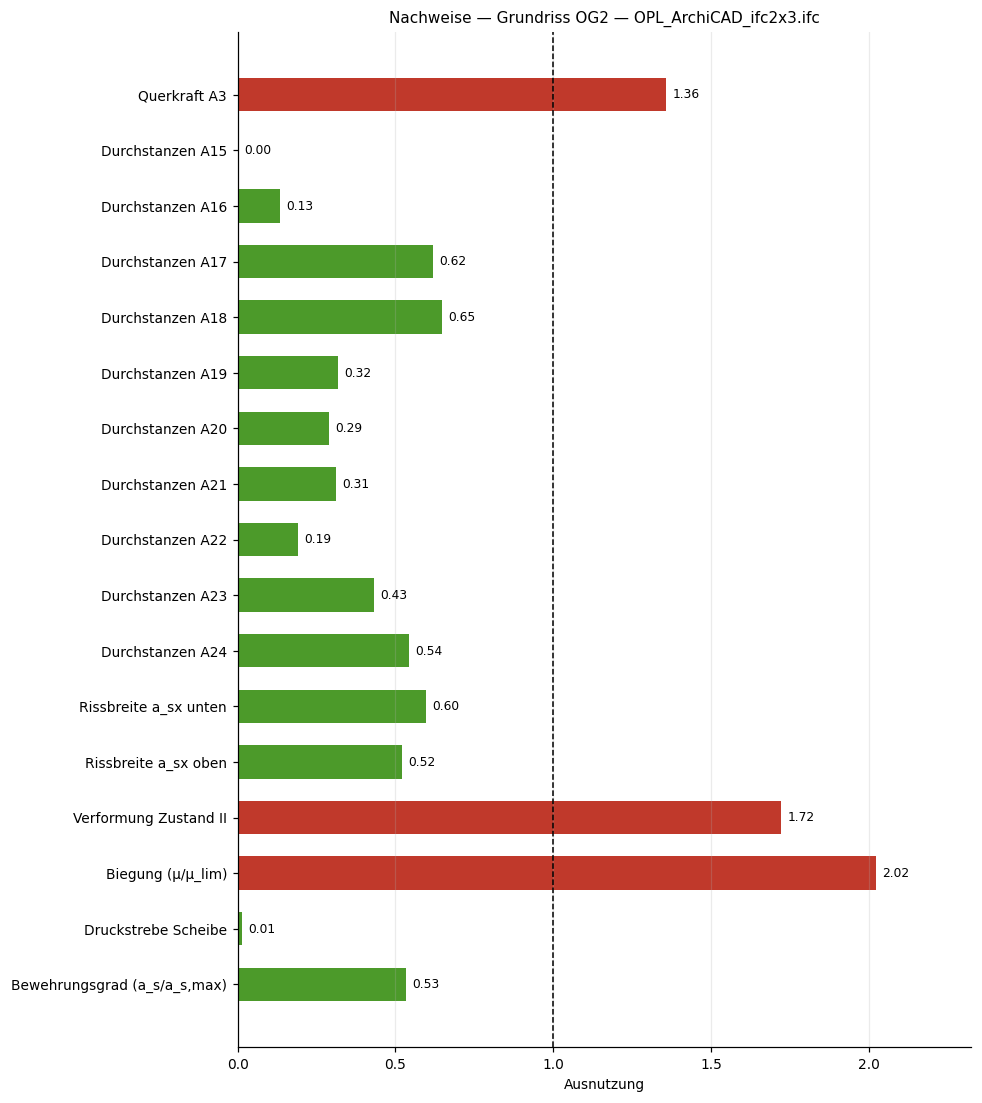

nicht erfüllt: Querkraft A3, Verformung Zustand II, Biegung (μ/μ_lim)


In [ ]:
fig, ax = plt.subplots(figsize=(9, 0.5 * len(nachweise) + 1.6))
zeichnen.ampel(ax, nachweise)
ax.set_title(f'Nachweise — {modell.titel}')
plt.tight_layout(); plt.show()

offen = [n for n, wert in nachweise if wert > 1.0]
print('nicht erfüllt:', ', '.join(offen) if offen else 'keiner — alle Nachweise erfüllt')

## 21. Rückbindung an das BIM-Modell und Export

Jede Position führt die GlobalIds ihrer Bauteile — genau die Verknüpfungen,
die im Plan mit dem Werkzeug ⚯ von Hand gesetzt wurden. Damit lassen sich die
Ergebnisse wieder am Bauteil zeigen, im Viewer oder in einer Prüfliste.

Die Exportdatei enthält, was ein Backend-Endpunkt zurückgeben müsste: Netz,
Kombinationen, Schnittgrößen, Bewehrung, Nachweise und die Zuordnung zu den
Bauteilen.

In [ ]:
zuordnung = plate.positionsbezug(modell)
print(f"{'Position':10s} {'Querschnitt':16s} {'Material':10s} Bauteile")
print('-' * 70)
for position in modell.positionen:
    print(f"{position['id']:10s} {str(position['querschnitt'] or '—'):16s} "
          f"{str(position['material'] or '—'):10s} {len(position['bauteile'])}× "
          f"{position['beschreibung'] or ''}"[:100])
print()
for global_id, positionen in zuordnung.items():
    print(f'  {global_id}  →  {", ".join(positionen)}')

Position   Querschnitt      Material   Bauteile
----------------------------------------------------------------------
W1         d = 19 cm        Stahlbeton 1× 
W2         d = 19 cm        Stahlbeton 3× 
D1         —                —          0× 
W3         d = 20 cm        Stahlbeton 1× 

  3JHyAFUYn81fRTfKgpn6$3  →  W1, W2
  37tTyXpjb3hh5PEXe7wBpz  →  W2
  2cxIKvjpX3rOWv2hKsK3Cx  →  W2
  35A1iF3B11QBjdUFooYy$s  →  W3


In [ ]:
bericht_json = {
    'quelle': DATEI.name,
    'plan': modell.daten.get('plan', {}),
    'netz': {'elemente': netz.n_elemente, 'knoten': netz.n_knoten,
             'elementgroesse_m': netz.groesse, 'lagen': plate.lagen(netz),
             'verfahren': netz.verfahren},
    'material': platte['material'],
    'geometrie': {'dicke_m': h, 'flaeche_m2': plate.flaeche(netz.polygon),
                  'spannweite_m': ergebnis['spannweite_m'],
                  'c_nom_mm': c_nom, 'd_x_m': d_x, 'd_y_m': d_y},
    'kombinationen': {k: {kk: round(vv, 3) for kk, vv in v.items()} for k, v in kombis.items()},
    'massgebend': name,
    'lastsummen_kN': {k: round(v, 1) for k, v in summen.items()},
    'auflager': bilanz,
    'momente_kNm_je_m': {
        'm_x_max': plate.hoechstwert(huellen['m_x']['max']),
        'm_x_min': -plate.hoechstwert(-huellen['m_x']['min']),
        'm_y_max': plate.hoechstwert(huellen['m_y']['max']),
        'm_y_min': -plate.hoechstwert(-huellen['m_y']['min']),
        'm_xy_max': plate.hoechstwert(np.abs(huellen['m_xy']['max']))},
    'unterzuege': {kennung: {
        'b_w_m': u['balken'].breite_m, 'h_m': u['balken'].hoehe_m,
        'laenge_m': round(u['balken'].laenge_m, 3),
        'b_eff_m': round(u['breite']['b_eff_m'], 3),
        'l_0_m': round(u['l_0_m'], 3),
        'M_max_kNm': round(float(np.max(u['schnitt']['M_max_kNm'])), 1),
        'M_min_kNm': round(float(np.min(u['schnitt']['M_min_kNm'])), 1),
        'V_max_kN': round(float(np.max(u['schnitt']['V_kN'])), 1),
        'a_s_unten_cm2': round(float(np.max(u['bemessung']['a_s_unten_cm2'])), 2),
        'a_s_oben_cm2': round(float(np.max(u['bemessung']['a_s_oben_cm2'])), 2),
        'grundbewehrung': u['staffelung_unten']['grund_bezeichnung'],
        'zulagen': u['staffelung_unten']['zulagen'],
        'buegel': u['buegel'],
        'lager_m': [round(l['s_m'], 3) for l in u['lager']],
    } for kennung, u in unterzuege.items()},
    'scheibe': {
        'q_p_kNm2': q_p, 'einzugshoehe_m': GESCHOSSHOEHE,
        'H_wind_kN': {k: [round(float(x), 2) for x in scheibe.gesamtkraft(v)]
                      for k, v in windlasten.items()},
        'H_imperfektion_kN': round(imp['H_kN'], 2), 'theta_i': round(imp['theta_i'], 5),
        'n_kNm': {k: [round(float(n_huelle[k]['min'].min()), 2),
                      round(float(n_huelle[k]['max'].max()), 2)] for k in n_huelle},
        'wandkraefte': wandbilanz[massgebende_richtung]},
    'bewehrung_cm2_je_m': {b: {'flaeche': round(bewehrung[b]['flaeche_cm2'], 2),
                                'spitze': round(plate.hoechstwert(bewehrung[b]['a_s']), 2)}
                           for b in bewehrung},
    'mindestbewehrung_cm2': round(a_s_min, 2),
    'staffelung': {'schnitt_y_m': round(float(y_schnitt), 3),
                   'grund': staffel['grund_bezeichnung'], 'zulagen': staffel['zulagen']},
    'nachweise': {n: round(float(w), 3) for n, w in nachweise},
    'positionen': {p['id']: p['bauteile'] for p in modell.positionen},
    'warnungen': modell.warnungen,
}

ziel = Path.cwd() / f'{DATEI.stem}_ergebnis.json'
ziel.write_text(json.dumps(bericht_json, indent=2, ensure_ascii=False, default=float),
                encoding='utf-8')
print('geschrieben:', ziel)
print(json.dumps(bericht_json['nachweise'], indent=2, ensure_ascii=False))

---

## Was das Modell nicht kann

Damit niemand mehr hineinliest, als drinsteht:

* **Elastische Bettung.** Federlager werden als starr gerechnet und gemeldet.
  Eine echte Bettung braucht Robin-Randbedingungen und damit eine eigene
  Problemklasse.
* **Durchlaufwirkung über Geschosse.** Gerechnet wird eine Decke, nicht das
  Gebäude. Die Einspannung in die Wände und die Weiterleitung in die
  Nachbardecke bleiben außen vor — beides liegt für die Feldbewehrung auf der
  sicheren Seite, für die Stützbewehrung nicht.
* **Torsion im Unterzug.** Ein Randunterzug unter einer auskragenden Platte
  bekommt ein Torsionsmoment, das hier nicht ermittelt wird — die Integration
  liefert Biegung und Längskraft, nicht das Moment um die Trägerachse. Bei
  Innenunterzügen mit beidseitiger Platte hebt es sich weitgehend auf.
* **Schräge Unterzüge.** Das Netz ist achsparallel, ein schräger Steg wäre
  eine Treppe. Solche Balken versteifen die Decke richtig, werden aber nicht
  bemessen (`unterzug.finde()` meldet sie).
* **Öffnungen.** Der Systemumriss ist ein einzelner Ring; Deckenöffnungen
  müssten als Innenring vernetzt werden. Bis dahin: Öffnung aus dem Umriss
  ausschneiden, indem man ihn um sie herumführt.
* **Zeitabhängigkeit.** Kriechen geht nur pauschal über φ in den
  Verformungsnachweis ein, Schwinden gar nicht.
* **Wandsteifigkeiten.** Die aussteifenden Wände sind starr. Die wirkliche
  Verteilung der Windlast folgt ihren Steifigkeiten und fällt für die einzelne
  Wand günstiger aus — die Rechnung liegt insoweit auf der sicheren Seite,
  taugt aber nicht zur Ermittlung der Gebäudeverformung.

## Was als Nächstes ins Backend gehört

```
POST /fem/plate          Body: die Exportdatei      → { result_id, status }
GET  /fem/plate/{id}     → Durchbiegung, Momente, Bewehrung, Nachweise
GET  /fem/plate/{id}/element/{global_id}   → Ergebnisse je Bauteil
```

`ileen/plate.py`, `ileen/loeser.py`, `ileen/scheibe.py` und `ileen/beton.py`
enthalten alles, was der Endpunkt braucht; hinzu käme die Ablage der
Ergebnisse und die Rückgabe an den Viewer, der sie über die GlobalId wieder am
Bauteil anzeigen kann — dieselbe Kette, die `SCHEMA.md` für die Gesamtstatik
beschreibt.